# Slice MEA analysis — `2024-06-04__Slice2_HET_S5E2_Chr2_eYFP_mPFC_Baseline__0004`

This notebook does two things for one 60-channel MCS slice recording (mPFC, HET, baseline):

**Part A — Spike/event detection, validation and sufficiency (reviewer response).**
It makes every detection choice explicit and saves it to disk, so the Methods can state exactly:
1. the **filter** and **sampling rate** used for detection, and whether data were **downsampled**;
2. the **signal representation** the amplitude-percentile threshold was applied to (signed voltage, absolute amplitude, …);
3. **what the events are** — single units (only if sorted), multi-unit activity (MUA), or population-level synchronous field events — and the **validation** used to tell them apart;
4. the **number and rate** of events per channel / layer;
5. whether the **5-min recording** holds **enough events** for connectivity and three-node motif estimation.

**Part B — LFP gamma (30–100 Hz) and HFO (120–200 Hz) band power** (your original cells 7–14, now with
corrected sampling-rate handling — see the warning below).

### ⚠️ Corrections relative to the original notebook (please read before re-using old outputs)
| # | Original behaviour | Consequence | Fix here |
|---|---|---|---|
| 1 | LFP downsampled to **10 kHz** (`target_sf = 10000`), but band-power cells declared `target_sf = 1000` and `window_size = 1000` samples | Welch frequency axis was scaled by 1/10: the "30–100 Hz gamma" band actually measured **300–1000 Hz**, the "120–200 Hz HFO" band measured **1.2–2 kHz** (above the 500 Hz low-pass, i.e. mostly filtered noise), and "1-s windows" were **0.1 s** (hence 5998 windows for 300 s) | One variable (`fs_lfp`) is returned by the downsampler and used everywhere; LFP downsampled to 1 kHz; windows defined in seconds |
| 2 | CP "latent weighting" used `factors.factors[1]` (the **time** mode) and broadcast it over channels | Shape mismatch → silently caught by bare `except` → **raw min-max-normalised power was saved** every time ("Using raw power…" in the outputs) | Default `APPLY_CP_CHANNEL_WEIGHTING = False` reproduces what was actually saved; `True` uses the channel mode `factors[0]` |
| 3 | 1-Hz high-pass Butterworth in `(b, a)` form at 20 kHz, applied causally with `lfilter` | `(b, a)` is numerically fragile at such low normalised cut-offs; causal filtering adds phase delay and waveform distortion | Second-order sections (`sos`) + zero-phase `sosfiltfilt` |
| 4 | `filter_dataLFP` had no `return` | Function returned `None` (unused, so no impact) | Removed |
| 5 | Plot labels said "13 ch" / "26 ch" | Actual channel counts are 14 (PrL L2/3) and 25 (PrL L5) | Labels computed from the data |
| 6 | Raw ADC counts used | Thresholds/amplitudes not in physical units | Converted to µV with the per-channel `InfoChannel` conversion factors |

Corrected LFP outputs are written to a **separate folder** so your previously saved `.npy` files are never overwritten.
Set `REPRODUCE_ORIGINAL_LFP = True` to regenerate the original (uncorrected) arrays for comparison.

### Outputs (all written under `OUT_DIR`)
* `detection_parameters.json` — every parameter + recording metadata + software versions
* `per_channel_summary.csv` — counts, rates, thresholds (µV and × noise SD), SNR, waveform width, ISI violations, population-event fraction, classification
* `per_layer_summary.csv`, `threshold_sensitivity.csv`, `all_events.csv`, `population_events.csv`, `spike_times.npz`, `median_waveforms.npz`
* `pairwise_sufficiency.csv`, `triplet_sufficiency.csv`, `sufficiency_summary.json`, `subsampling_stability.csv`
* `figures/*.png|pdf` — example traces with threshold, waveforms, rates, raster, rate stationarity, sufficiency
* `METHODS_and_reviewer_response.md` — Methods paragraph and point-by-point answers **filled in with this recording's numbers**
* `run_manifest.json` — list of every file written

## 0. Environment
Runs in Google Colab (mounts Drive) and also runs locally (Colab-only steps are skipped).

In [1]:
from scipy.signal import butter, lfilter
from scipy import signal
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn as sk
import h5py
import os.path
import pandas as pd
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.cluster import MiniBatchKMeans
from sklearn.metrics import silhouette_score
from sklearn.cluster import DBSCAN
from tensorly.decomposition import parafac
from tensorly.cp_tensor import cp_to_tensor
import tensorly as tl
from scipy.signal import welch
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import MinMaxScaler
from sklearn.model_selection import train_test_split
import tensorflow as tf
#import librosa.display
# !pip install tensorly
# from kneed import KneeLocator
# !pip install numpy==1.21.6 scipy==1.7.3
# pip install --upgrade tensorly
import os, sys

# tensorly is not pre-installed on Colab; install only if missing.
try:
    import tensorly
except ImportError:
    get_ipython().run_line_magic('pip', 'install -q tensorly')

2026-10-11 05:30:55.594475: I tensorflow/core/util/port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
2026-10-11 05:30:55.595802: I external/local_xla/xla/tsl/cuda/cudart_stub.cc:32] Could not find cuda drivers on your machine, GPU will not be used.
2026-10-11 05:30:55.598563: I external/local_xla/xla/tsl/cuda/cudart_stub.cc:32] Could not find cuda drivers on your machine, GPU will not be used.
2026-10-11 05:30:55.612180: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:477] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1791711055.639649 3973704 cuda_dnn.cc:8310] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1791711055.64

## 1. Configuration — the only cell you should need to edit
Every analysis choice lives here, with its rationale, and is written verbatim to `detection_parameters.json`.

> **Important:** `THRESHOLD_SIGNAL`, `THRESHOLD_PERCENTILE`, `DEAD_TIME_MS` and `CONN_LAG_WINDOW_MS` must be set to
> the values that generated the spike data used in your motif analysis. The numbers you report have to describe the
> pipeline that produced the figure.

In [2]:
data_path = "/home/hosseini/Desktop/2024/CNN_samples"

# ----------------------------------------------------------------------------- identity / paths
RECORDING_FILE = data_path + "/2024-01-22mPFC_Slice1_LC_to_mPFC_hsyn_ChR2_eYFP_Vehicle_KO__0005.h5"
SAMPLE_ID  = "2024-01-22_mPFC_Slice1"        # prefix of saved files (same as your original naming)
GENOTYPE   = "KO"
CONDITION  = "Baseline"
BASE_OUT_DIR = "/home/hosseini/Desktop/CNN/Spike Detection/Output"

# ----------------------------------------------------------------------------- acquisition
EXPECTED_FS_HZ = 20000         # nominal MCS sampling rate; verified against the file's InfoChannel 'Tick'

# ----------------------------------------------------------------------------- spike / event detection
# Band-pass for detection. 300-3000 Hz is the standard extracellular spike band: the lower edge removes
# LFP (incl. gamma/HFO, which are analysed separately in Part B) so that slow field potentials cannot cross
# the threshold; the upper edge removes high-frequency amplifier noise while keeping the ~0.3-1 ms spike
# waveform. Applied forward+backward (zero phase) so event timing is not shifted - essential when relative
# spike timing between channels is used for directed connectivity.
SPIKE_BAND_HZ      = (300.0, 3000.0)
SPIKE_FILTER_ORDER = 4         # Butterworth order per pass (zero-phase -> effective 8th-order magnitude response)

# Detection runs at the native sampling rate (no downsampling): spikes last ~1 ms, so 20 kHz gives
# 0.05-ms timing resolution and ~20 samples per waveform; downsampling would blur peak times and widths.
DOWNSAMPLE_FOR_DETECTION = False   # kept as an explicit, reported flag; detection code never downsamples

# Signal representation the percentile threshold is applied to:
#   'negative' : signed band-passed voltage, events = samples BELOW the (100 - P)th percentile
#                (extracellular somatic spikes are predominantly negative-going)
#   'positive' : signed voltage, events = samples ABOVE the P-th percentile
#   'absolute' : |voltage|, events = samples above the P-th percentile of |x| (either polarity)
THRESHOLD_SIGNAL     = "negative"  # <-- set to what your motif pipeline used
THRESHOLD_PERCENTILE = 99.9        # <-- set to what your motif pipeline used (P; 99.9 => 0.1 % of samples)

# Each contiguous supra-threshold run is one candidate event, timed at its extremum; a dead time then merges
# re-crossings by the same waveform (1 ms ~ one spike duration / absolute refractory period).
DEAD_TIME_MS = 1.0

# Noise estimate used to express the percentile threshold in interpretable units (Quiroga et al., 2004):
# sigma_noise = median(|x|) / 0.6745. Robust to the spikes themselves, unlike the plain SD.
MAD_K_FOR_SENSITIVITY = (4.0, 5.0) # noise-referenced thresholds used only for the sensitivity comparison

# Waveform extraction (for validation only).
WAVEFORM_PRE_MS, WAVEFORM_POST_MS = 1.0, 1.5
MAX_WAVEFORMS_FOR_MEDIAN = 2000
N_WAVEFORMS_TO_PLOT      = 50

# ----------------------------------------------------------------------------- event validation / classification
# Population-level synchronous events: a single neuron's spike is visible on at most 1-2 neighbouring
# electrodes of a 60-channel MEA (pitch 100-200 um), so an event that appears within +/-0.5 ms on a large
# fraction of channels cannot be local unit activity; it is a population field event (or a shared artefact).
POP_COINCIDENCE_MS         = 0.5
POP_MIN_FRACTION_CHANNELS  = 0.5   # >= 50 % of analysed channels -> population event
# A channel is labelled MUA only if:
MIN_THRESHOLD_IN_NOISE_SD  = 4.0   # percentile threshold >= 4 x sigma_noise (otherwise noise crossings dominate)
MAX_POP_EVENT_FRACTION     = 0.20  # <= 20 % of its events are population events
ISI_VIOLATION_MS           = 1.5   # reported only: MUA pools several neurons, so violations are expected

# ----------------------------------------------------------------------------- sufficiency for connectivity / motifs
# Directed coincidence window: spikes of j in (t_i + lo, t_i + hi]. 0.5 ms lower bound excludes zero-lag
# synchrony (population events / shared artefacts); 5 ms upper bound covers mono-/di-synaptic latencies.
CONN_LAG_WINDOW_MS = (0.5, 5.0)    # <-- set to the lag window of your connectivity estimator
CONN_Z_THRESHOLD   = 3.0           # Poisson z for a "significant" directed edge
# A directed pair is 'adequately sampled' if the number of coincidences expected by chance is >= 10.
# With E = 10, a z = 3 excess needs ~95 % more coincidences than chance (3/sqrt(E)); with E < 10 only very
# strong couplings are detectable and the Poisson-normal approximation is poor.
MIN_EXPECTED_COINCIDENCES = 10
MIN_EVENTS_PER_CHANNEL    = 100    # floor: 100 events / 300 s = 0.33 Hz
# Heuristic criteria for the overall 'sufficient' verdict (always reported together with the raw metrics).
# Split-half reliability metric: 'jaccard_sig_edges' (overlap of significant directed edges between halves)
# is preferred over the Spearman rho of all z-values, because in a sparse network most pairs have no true
# coupling, so their z-values are pure noise and pull rho toward 0 however many events there are.
SUFF_MIN_FRAC_PAIRS_ADEQUATE    = 0.80
SUFF_RELIABILITY_METRIC         = "jaccard_sig_edges"   # or 'rho_z' or 'rho_triad_census'
SUFF_MIN_SPLIT_HALF_RELIABILITY = 0.50
SUBSAMPLE_FRACTIONS = (0.25, 0.50, 0.75)
N_SUBSAMPLE_REPS    = 20
RATE_BIN_S          = 10.0         # bin for the rate-stationarity plot
EXAMPLE_TRACE_S     = 2.0          # length of example filtered traces stored for plotting
RANDOM_SEED         = 0

# ----------------------------------------------------------------------------- Part B: LFP
REPRODUCE_ORIGINAL_LFP     = False # True = regenerate the original (uncorrected) arrays, see table above
APPLY_CP_CHANNEL_WEIGHTING = False # False = what was actually saved originally (raw min-max power)
LFP_BAND_HZ       = (1.0, 500.0)
LFP_FILTER_ORDER  = 2
LFP_TARGET_FS     = 1000           # Hz; Nyquist 500 Hz covers gamma (30-100) and HFO (120-200)
LINE_NOISE_HZ, NOTCH_Q = 60.0, 30
BP_WINDOW_S, BP_STRIDE_S = 1.0, 0.5   # 1-s windows, 50 % overlap
WELCH_NPERSEG     = 256            # at 1 kHz -> 3.9 Hz frequency resolution
GAMMA_BAND_HZ, HFO_BAND_HZ = (30, 100), (120, 200)
CP_RANKS          = range(1, 6)

# ----------------------------------------------------------------------------- output folders
rec_stem = os.path.splitext(os.path.basename(RECORDING_FILE))[0]
OUT_DIR  = os.path.join(BASE_OUT_DIR, GENOTYPE, "spike_detection", f"{SAMPLE_ID}__{rec_stem}")
FIG_DIR  = os.path.join(OUT_DIR, "figures")
LFP_OUT_DIR = (os.path.join(BASE_OUT_DIR, GENOTYPE) if REPRODUCE_ORIGINAL_LFP   # original location/names
               else os.path.join(BASE_OUT_DIR, GENOTYPE, "lfp_power_corrected_fs"))
for d in (OUT_DIR, FIG_DIR, LFP_OUT_DIR):
    os.makedirs(d, exist_ok=True)
print("Spike outputs ->", OUT_DIR)
print("LFP outputs   ->", LFP_OUT_DIR)

Spike outputs -> /home/hosseini/Desktop/CNN/Spike Detection/Output/KO/spike_detection/2024-01-22_mPFC_Slice1__2024-01-22mPFC_Slice1_LC_to_mPFC_hsyn_ChR2_eYFP_Vehicle_KO__0005
LFP outputs   -> /home/hosseini/Desktop/CNN/Spike Detection/Output/KO/lfp_power_corrected_fs


## 2. Imports and small utilities

In [3]:
import json, itertools, platform, datetime, warnings
import numpy as np
import pandas as pd
import h5py
import matplotlib
import matplotlib.pyplot as plt
import scipy
from scipy import signal
from scipy.signal import butter, sosfiltfilt, filtfilt, lfilter, iirnotch, welch
from scipy.stats import spearmanr
from sklearn.preprocessing import MinMaxScaler
import tensorly as tl
from tensorly.decomposition import parafac
try:
    import networkx as nx       # used only for the triad (3-node motif) census stability check
    HAVE_NX = True
except ImportError:
    HAVE_NX = False

rng = np.random.default_rng(RANDOM_SEED)
WRITTEN_FILES = []              # every saved path is recorded here -> run_manifest.json

def _record(path):
    WRITTEN_FILES.append(os.path.abspath(path))
    print("  saved:", path)

def save_fig(fig, name):
    """Save a figure as 300-dpi PNG (viewing) and PDF (vector, for the manuscript)."""
    for ext in ("png", "pdf"):
        p = os.path.join(FIG_DIR, f"{SAMPLE_ID}_{name}.{ext}")
        fig.savefig(p, dpi=300, bbox_inches="tight")
        _record(p)

def save_csv(df, name, directory=None):
    p = os.path.join(directory or OUT_DIR, f"{SAMPLE_ID}_{name}.csv")
    df.to_csv(p, index=False)
    _record(p)

def save_json(obj, name, directory=None):
    p = os.path.join(directory or OUT_DIR, f"{SAMPLE_ID}_{name}.json")
    with open(p, "w") as f:
        json.dump(obj, f, indent=2, default=lambda o: o.item() if hasattr(o, "item") else str(o))
    _record(p)

## 3. Load the recording and convert to µV
The sampling rate and the ADC→volt conversion are read from the file's `InfoChannel` table rather than assumed,
so the reported sampling rate is the one actually stored with the data.

In [4]:
with h5py.File(RECORDING_FILE, "r") as hdf:
    stream = hdf["Data/Recording_0/AnalogStream/Stream_0"]
    ChannelData_baseline = np.array(stream["ChannelData"])          # (channels, samples), raw ADC counts
    info_channel = stream["InfoChannel"][()] if "InfoChannel" in stream else None

n_rows, n_samples = ChannelData_baseline.shape

def _dec(v):
    return v.decode() if isinstance(v, (bytes, np.bytes_)) else str(v)

# Per-row conversion: value[unit] = (raw - ADZero) * ConversionFactor * 10**Exponent ; unit is volts for MCS.
ad_zero      = np.zeros(n_rows)
uV_per_count = np.ones(n_rows)
file_labels  = [None] * n_rows
UNITS = "ADC counts"
sf = EXPECTED_FS_HZ
if info_channel is not None:
    rows = info_channel["RowIndex"].astype(int)
    for k, r in enumerate(rows):
        ad_zero[r]      = float(info_channel["ADZero"][k])
        uV_per_count[r] = float(info_channel["ConversionFactor"][k]) * 10.0 ** float(info_channel["Exponent"][k]) * 1e6
        file_labels[r]  = _dec(info_channel["Label"][k])
    unit_str = _dec(info_channel["Unit"][0])
    if unit_str.strip() == "V":
        UNITS = "uV"
    else:
        warnings.warn(f"Unexpected unit '{unit_str}'; values are scaled by 1e6 x the stored unit.")
        UNITS = f"1e-6 {unit_str}"
    ticks = np.unique(info_channel["Tick"])
    sf = int(round(1e6 / float(ticks[0])))                          # Tick = sample interval in microseconds
    if sf != EXPECTED_FS_HZ:
        warnings.warn(f"File sampling rate {sf} Hz differs from EXPECTED_FS_HZ={EXPECTED_FS_HZ}; using {sf} Hz.")
else:
    warnings.warn("No InfoChannel table: amplitudes stay in ADC counts and fs is assumed.")

duration_s = n_samples / sf
print(f"Data shape {ChannelData_baseline.shape} | fs = {sf} Hz | duration = {duration_s:.1f} s "
      f"({duration_s/60:.2f} min) | units: {UNITS}")

def to_uV(row):
    """One channel in uV (float64)."""
    return (ChannelData_baseline[row].astype(np.float64) - ad_zero[row]) * uV_per_count[row]

Data shape (60, 6060000) | fs = 20000 Hz | duration = 303.0 s (5.05 min) | units: uV


## 4. Channel map and layer assignment
Same electrode→row map and layer lists as before. The map is now **checked against the electrode labels stored in
the file**; a mismatch would mean channels were assigned to the wrong layer.

In [5]:
unwanted_num = [14,12]   # electrodes excluded (noisy / reference / outside tissue)

# MCS electrode label (column-row, e.g. 54) -> row index in ChannelData
numbers_dict = {
    54: 0, 56: 1, 55: 2, 46: 3, 45: 4, 44: 5, 36: 6, 35: 7, 34: 8, 26: 9,
    16: 10, 25: 11, 15: 12, 24: 13, 14: 14, 13: 15, 23: 16, 12: 17, 22: 18,
    11: 19, 21: 20, 33: 21, 32: 22, 31: 23, 43: 24, 42: 25, 41: 26, 52: 27,
    51: 28, 53: 29, 63: 30, 61: 31, 62: 32, 71: 33, 72: 34, 73: 35, 81: 36,
    82: 37, 83: 38, 91: 39, 101: 40, 92: 41, 102: 42, 93: 43, 103: 44,
    104: 45, 94: 46, 105: 47, 95: 48, 106: 49, 96: 50, 84: 51, 85: 52,
    86: 53, 74: 54, 75: 55, 76: 56, 65: 57, 66: 58, 64: 59,
}
row_to_label = {v: k for k, v in numbers_dict.items()}

def get_corresponding_values(selected_nums):
    """Electrode labels -> data rows, dropping excluded electrodes."""
    return [numbers_dict[n] for n in selected_nums if n not in unwanted_num and n in numbers_dict]

# Layer assignment by electrode position over the slice (unchanged from the original notebook)
PrL_L5 = get_corresponding_values([
#     11,21,31,
    41,51,61,71,81,91,101,
#     12,22,32,
    42,52,62,72,92,102,
#     13,23,43,
    53,63,73,83,93,103,
#     24,34,
    54,64,74,84,94,104,
#     15,25,35,
#     45,55,65,75,85,95,105,
#     16,26,36,
#     46,56,66,76,86,96,106,
])

PrL_L23 = get_corresponding_values([
#     11,21,31,
#     41,51,61,71,81,91,101,
#     12,22,32,
#     42,52,62,72,92,102,
#     13,23,43,
#     53,63,73,83,93,103,
#     24,34,
#     54,64,74,84,94,104,
#     15,25,35,
    45,55,65,75,85,95,105,
#     16,26,36,
    46,56,66,76,86,96,106,
])




IL_L5 = get_corresponding_values([
    11,21,31,
#     41,51,61,71,81,91,101,
    12,22,32,
#     42,52,62,72,92,102,
    13,23,43,
#     53,63,73,83,93,103,
    24,34,
#     54,64,74,84,94,104,
#     15,25,35,
#     45,55,65,75,85,95,105,
#     16,26,36,
#     46,56,66,76,86,96,106,
])

IL_L23 = get_corresponding_values([
#     11,21,31,
#     41,51,61,71,81,91,101,
#     12,22,32,
#     42,52,62,72,92,102,
#     13,23,43,
#     53,63,73,83,93,103,
#     24,34,
#     54,64,74,84,94,104,
    15,25,35,
#     45,55,65,75,85,95,105,
    16,26,36,
#     46,56,66,76,86,96,106,
])

# Layers analysed (add IL_L23 / IL_L5 here if they enter the motif analysis)
LAYERS = {"PrL_L23": PrL_L23, "PrL_L5": PrL_L5}
for name, rows_ in LAYERS.items():
    print(f"{name}: {len(rows_)} channels, electrodes {[row_to_label[r] for r in rows_]}")

# Verify the hand-made map against the labels stored in the recording
map_mismatches = []
for r, lab in enumerate(file_labels):
    if lab is not None and lab.strip().isdigit():
        e = int(lab)
        if e in numbers_dict and numbers_dict[e] != r:
            map_mismatches.append({"electrode": e, "map_row": numbers_dict[e], "file_row": r})
if any(l is None for l in file_labels):
    print("Channel-map check skipped (no labels in file).")
elif map_mismatches:
    warnings.warn(f"CHANNEL MAP DOES NOT MATCH FILE LABELS for {len(map_mismatches)} electrodes: {map_mismatches[:5]} ...")
else:
    print("Channel map verified against file labels: all electrodes match.")

PrL_L23: 14 channels, electrodes [45, 55, 65, 75, 85, 95, 105, 46, 56, 66, 76, 86, 96, 106]
PrL_L5: 25 channels, electrodes [41, 51, 61, 71, 81, 91, 101, 42, 52, 62, 72, 92, 102, 53, 63, 73, 83, 93, 103, 54, 64, 74, 84, 94, 104]
Channel map verified against file labels: all electrodes match.


# Part A — Spike / event detection, validation and sufficiency

### 5. Detection functions
**Pipeline per channel:** raw → µV → 300–3000 Hz zero-phase Butterworth (native 20 kHz, no downsampling) →
percentile threshold on the chosen signal representation → one event per supra-threshold run (at its extremum) →
dead time.

**Why the threshold is also expressed in noise-SD units.** A percentile threshold labels a *fixed fraction of samples*
as supra-threshold on every channel. On a quiet channel that fraction is made of noise, so the event count is partly
set by construction rather than by activity. Converting each channel's percentile threshold to multiples of the
robust noise SD (σ = median|x|/0.6745) shows whether it sits in the range normally used for spikes (≈4–5 σ), and the
sensitivity table compares counts with noise-referenced thresholds.

In [6]:
SOS_SPIKE   = butter(SPIKE_FILTER_ORDER, SPIKE_BAND_HZ, btype="bandpass", fs=sf, output="sos")
DEAD_SAMPLES = int(round(DEAD_TIME_MS * 1e-3 * sf))
WF_PRE, WF_POST = int(round(WAVEFORM_PRE_MS * 1e-3 * sf)), int(round(WAVEFORM_POST_MS * 1e-3 * sf))

def robust_noise_sd(x):
    """Quiroga et al. (2004) noise estimate: median(|x|)/0.6745."""
    return np.median(np.abs(x)) / 0.6745

def detection_score(x, mode):
    """Signal representation the threshold is applied to (larger = more event-like)."""
    if mode == "negative":
        return -x
    if mode == "positive":
        return x
    if mode == "absolute":
        return np.abs(x)
    raise ValueError(mode)

def percentile_threshold(x, mode, percentile):
    """Threshold magnitude on the detection score; for 'negative' this is -(100-P)th percentile of signed x."""
    if mode == "negative":
        return -np.percentile(x, 100.0 - percentile)
    if mode == "positive":
        return np.percentile(x, percentile)
    return np.percentile(np.abs(x), percentile)

def detect_events(x, mode, thr_mag, dead_samples):
    """
    Threshold crossings -> one event per contiguous supra-threshold run (at the run's extremum)
    -> dead time: of two events closer than `dead_samples`, the larger one is kept.
    Returns sample indices of event peaks.
    """
    score = detection_score(x, mode)
    supra = score > thr_mag
    if not supra.any():
        return np.array([], dtype=np.int64)
    edges  = np.diff(supra.astype(np.int8))
    starts = np.flatnonzero(edges == 1) + 1
    ends   = np.flatnonzero(edges == -1) + 1
    if supra[0]:
        starts = np.r_[0, starts]
    if supra[-1]:
        ends = np.r_[ends, len(x)]
    peaks = np.fromiter((s + np.argmax(score[s:e]) for s, e in zip(starts, ends)),
                        dtype=np.int64, count=len(starts))
    kept = []
    for p in peaks:
        if kept and p - kept[-1] < dead_samples:
            if score[p] > score[kept[-1]]:
                kept[-1] = p
        else:
            kept.append(p)
    return np.asarray(kept, dtype=np.int64)

### 6. Run detection on every analysed channel
Also computes, per channel: noise SD, threshold in µV and in noise-SD units, median waveform, trough-to-peak width,
SNR, ISI violations, and the event counts obtained with alternative thresholds (sensitivity analysis).

In [7]:
records, sens_rows = [], []
spike_times, spike_amps = {}, {}
median_wfs, example_wfs, example_traces, thr_signed_by_key = {}, {}, {}, {}
wf_t_ms = np.arange(-WF_PRE, WF_POST + 1) / sf * 1e3

for layer, rows_ in LAYERS.items():
    for row in rows_:
        elec = row_to_label[row]
        key = f"{layer}_E{elec}"
        x = sosfiltfilt(SOS_SPIKE, to_uV(row))                       # zero-phase, native fs
        sigma = robust_noise_sd(x)

        thr_mag = percentile_threshold(x, THRESHOLD_SIGNAL, THRESHOLD_PERCENTILE)
        peaks = detect_events(x, THRESHOLD_SIGNAL, thr_mag, DEAD_SAMPLES)
        t = peaks / sf
        spike_times[key], spike_amps[key] = t, x[peaks]
        thr_signed_by_key[key] = {"negative": [-thr_mag], "positive": [thr_mag],
                                  "absolute": [-thr_mag, thr_mag]}[THRESHOLD_SIGNAL]
        example_traces[key] = x[: int(EXAMPLE_TRACE_S * sf)].astype(np.float32)

        # ---- waveform-based validation
        valid = peaks[(peaks >= WF_PRE) & (peaks < len(x) - WF_POST)]
        width_ms = p2p = np.nan
        if len(valid):
            sel = np.sort(rng.choice(valid, size=min(len(valid), MAX_WAVEFORMS_FOR_MEDIAN), replace=False))
            wf = x[sel[:, None] + np.arange(-WF_PRE, WF_POST + 1)]
            med = np.median(wf, axis=0)
            median_wfs[key] = med
            example_wfs[key] = wf[: N_WAVEFORMS_TO_PLOT]
            i_tr = int(np.argmin(med))
            i_pk = i_tr + int(np.argmax(med[i_tr:]))
            width_ms = (i_pk - i_tr) / sf * 1e3                       # trough-to-peak width of the median waveform
            p2p = float(med.max() - med.min())
        isi = np.diff(t)
        records.append({
            "layer": layer, "electrode": elec, "data_row": row, "key": key,
            "n_events": len(peaks), "rate_hz": len(peaks) / duration_s,
            "noise_sd_uV": sigma, "threshold_uV": thr_signed_by_key[key][0] if THRESHOLD_SIGNAL != "absolute" else thr_mag,
            "threshold_x_noise_sd": thr_mag / sigma,
            "median_abs_peak_uV": float(np.median(np.abs(x[peaks]))) if len(peaks) else np.nan,
            "snr_peak": float(np.median(np.abs(x[peaks]))) / sigma if len(peaks) else np.nan,
            "median_wf_p2p_uV": p2p, "trough_to_peak_ms": width_ms,
            "isi_violation_pct": 100 * float(np.mean(isi < ISI_VIOLATION_MS / 1e3)) if len(isi) else np.nan,
        })

        # ---- sensitivity: same data, alternative threshold definitions
        srow = {"key": key, "layer": layer, "electrode": elec}
        for mode in ("negative", "positive", "absolute"):
            m = percentile_threshold(x, mode, THRESHOLD_PERCENTILE)
            srow[f"n_{mode}_P{THRESHOLD_PERCENTILE}"] = len(detect_events(x, mode, m, DEAD_SAMPLES))
        for k in MAD_K_FOR_SENSITIVITY:
            srow[f"n_negative_{k:g}xMADsd"] = len(detect_events(x, "negative", k * sigma, DEAD_SAMPLES))
        sens_rows.append(srow)
        print(f"{key:16s} n={len(peaks):6d}  rate={len(peaks)/duration_s:6.2f} Hz  "
              f"thr={thr_mag/sigma:4.1f} x noise SD  SNR={records[-1]['snr_peak']:.1f}")
        del x

df_ch   = pd.DataFrame(records)
df_sens = pd.DataFrame(sens_rows)
CH_KEYS = list(spike_times.keys())

PrL_L23_E45      n=  3374  rate= 11.14 Hz  thr= 3.1 x noise SD  SNR=3.3
PrL_L23_E55      n=  3482  rate= 11.49 Hz  thr= 3.1 x noise SD  SNR=3.4
PrL_L23_E65      n=  3463  rate= 11.43 Hz  thr= 3.1 x noise SD  SNR=3.4
PrL_L23_E75      n=  3265  rate= 10.78 Hz  thr= 3.2 x noise SD  SNR=3.4
PrL_L23_E85      n=  3349  rate= 11.05 Hz  thr= 3.2 x noise SD  SNR=3.4
PrL_L23_E95      n=  3501  rate= 11.55 Hz  thr= 3.1 x noise SD  SNR=3.3
PrL_L23_E105     n=  3493  rate= 11.53 Hz  thr= 3.1 x noise SD  SNR=3.4
PrL_L23_E46      n=  3470  rate= 11.45 Hz  thr= 3.1 x noise SD  SNR=3.4
PrL_L23_E56      n=  3482  rate= 11.49 Hz  thr= 3.1 x noise SD  SNR=3.3
PrL_L23_E66      n=  3317  rate= 10.95 Hz  thr= 3.1 x noise SD  SNR=3.3
PrL_L23_E76      n=  3398  rate= 11.21 Hz  thr= 3.1 x noise SD  SNR=3.3
PrL_L23_E86      n=  3512  rate= 11.59 Hz  thr= 3.1 x noise SD  SNR=3.3
PrL_L23_E96      n=  3542  rate= 11.69 Hz  thr= 3.1 x noise SD  SNR=3.3
PrL_L23_E106     n=  3501  rate= 11.55 Hz  thr= 3.1 x noise SD  

### 7. Population-level events and channel classification
For every event, count how many *other* analysed channels have an event within ±`POP_COINCIDENCE_MS`. Events seen on
≥ `POP_MIN_FRACTION_CHANNELS` of channels are **population-level synchronous events** (sharp field events or shared
artefacts), not local unit activity.

No spike sorting is performed, so no event is attributed to a single neuron. A channel is labelled **MUA** if its
threshold is at least `MIN_THRESHOLD_IN_NOISE_SD` × noise SD, it has ≥ `MIN_EVENTS_PER_CHANNEL` events, and
≤ `MAX_POP_EVENT_FRACTION` of its events are population events.

In [8]:
tol = POP_COINCIDENCE_MS / 1e3
n_ch = len(CH_KEYS)
pop_min_channels = max(2, int(np.ceil(POP_MIN_FRACTION_CHANNELS * n_ch)))

# number of other channels coincident with each event
n_coinc = {k: np.zeros(len(spike_times[k]), dtype=int) for k in CH_KEYS}
for a in CH_KEYS:
    ta = spike_times[a]
    if len(ta) == 0:
        continue
    for b in CH_KEYS:
        tb = spike_times[b]
        if a == b or len(tb) == 0:
            continue
        n_coinc[a] += (np.searchsorted(tb, ta + tol, "right") > np.searchsorted(tb, ta - tol, "left"))
is_pop = {k: (n_coinc[k] + 1) >= pop_min_channels for k in CH_KEYS}
df_ch["pop_event_fraction"] = [float(is_pop[k].mean()) if len(is_pop[k]) else np.nan for k in df_ch["key"]]
df_ch["n_events_excl_pop"]  = [int((~is_pop[k]).sum()) for k in df_ch["key"]]
df_ch["rate_hz_excl_pop"]   = df_ch["n_events_excl_pop"] / duration_s

# list of population events (clusters of events chained within the tolerance, spanning >= pop_min_channels)
all_t   = np.concatenate([spike_times[k] for k in CH_KEYS]) if n_ch else np.array([])
all_ch  = np.concatenate([np.full(len(spike_times[k]), i) for i, k in enumerate(CH_KEYS)]) if n_ch else np.array([])
order   = np.argsort(all_t); all_t, all_ch = all_t[order], all_ch[order]
breaks  = np.flatnonzero(np.diff(all_t) > tol) + 1
pop_events = []
for seg_t, seg_c in zip(np.split(all_t, breaks), np.split(all_ch, breaks)):
    if len(seg_t) >= pop_min_channels:
        nu = len(np.unique(seg_c))
        if nu >= pop_min_channels:
            pop_events.append({"time_s": float(seg_t.mean()), "n_channels": int(nu),
                               "span_ms": float((seg_t[-1] - seg_t[0]) * 1e3)})
df_pop = pd.DataFrame(pop_events, columns=["time_s", "n_channels", "span_ms"])

def classify(r):
    if r.threshold_x_noise_sd < MIN_THRESHOLD_IN_NOISE_SD:
        return "noise-dominated (threshold < %.0f x noise SD)" % MIN_THRESHOLD_IN_NOISE_SD
    if r.n_events < MIN_EVENTS_PER_CHANNEL:
        return "too few events"
    if r.pop_event_fraction > MAX_POP_EVENT_FRACTION:
        return "population-event dominated"
    return "MUA"
df_ch["classification"] = df_ch.apply(classify, axis=1)

print(f"Population-event criterion: >= {pop_min_channels}/{n_ch} channels within +/-{POP_COINCIDENCE_MS} ms")
print(f"Population events: {len(df_pop)} ({len(df_pop)/duration_s:.3f} Hz)")
print(df_ch["classification"].value_counts().to_string())

Population-event criterion: >= 20/39 channels within +/-0.5 ms
Population events: 0 (0.000 Hz)
noise-dominated (threshold < 4 x noise SD)    39


### 8. Is 5 minutes enough? Sampling adequacy for connectivity and three-node motifs
Four complementary checks, all computed with the same lag window as the connectivity estimate:

1. **Expected chance coincidences per directed pair**, E = nᵢ·nⱼ·Δτ/T. With few events, E is small and only very strong
   couplings can reach significance; the *minimum detectable relative excess* at z = 3 is 3/√E.
2. **Triplet adequacy**: a three-node motif can only be estimated if all three of its pairs are adequately sampled.
3. **Split-half reliability**: connectivity z-matrix (and triad census, a generic 3-node motif count) from the first vs
   second 150 s. Agreement between independent halves is a direct test of whether the event count supports a
   stable estimate.
4. **Subsampling**: randomly thin every train to 25/50/75 % and compare to the full estimate. If the estimate is still
   changing steeply at 75 %, the full recording is not yet in a stable regime.

*Interpretation:* split-half Spearman ρ over **all** pairs is attenuated by uncoupled pairs (their z is noise), so the
verdict uses the overlap of significant edges by default. Subsampled estimates share events with the full data, so
those curves describe convergence, not independent reliability.
*Note:* the Poisson null ignores rate non-stationarity; the rate-over-time plot (section 9) shows whether that is a concern.
Replace the triad census with your own motif function if you want the identical statistic.

In [9]:
LAG_LO, LAG_HI = CONN_LAG_WINDOW_MS[0] / 1e3, CONN_LAG_WINDOW_MS[1] / 1e3
TRIADS_CONNECTED = ["021D", "021U", "021C", "111D", "111U", "030T", "030C",
                    "201", "120D", "120U", "120C", "210", "300"]

def directed_conn(trains, T):
    """C[i,j] = # spikes of j in (t_i+lo, t_i+hi]; E = chance expectation; Z = (C-E)/sqrt(E)."""
    n = len(trains)
    counts = np.array([len(t) for t in trains], dtype=float)
    C = np.zeros((n, n))
    for i, ti in enumerate(trains):
        if len(ti) == 0:
            continue
        for j, tj in enumerate(trains):
            if i != j and len(tj):
                C[i, j] = np.sum(np.searchsorted(tj, ti + LAG_HI, "right") - np.searchsorted(tj, ti + LAG_LO, "right"))
    E = np.outer(counts, counts) * (LAG_HI - LAG_LO) / T
    np.fill_diagonal(E, 0)
    with np.errstate(divide="ignore", invalid="ignore"):
        Z = np.where(E > 0, (C - E) / np.sqrt(E), np.nan)
    np.fill_diagonal(Z, np.nan)
    return C, E, Z

offdiag = ~np.eye(n_ch, dtype=bool)

def z_agreement(Za, Zb):
    m = offdiag & np.isfinite(Za) & np.isfinite(Zb)
    rho = spearmanr(Za[m], Zb[m]).correlation if m.sum() > 2 else np.nan
    sa, sb = (Za > CONN_Z_THRESHOLD) & m, (Zb > CONN_Z_THRESHOLD) & m
    union = (sa | sb).sum()
    return rho, ((sa & sb).sum() / union) if union else np.nan

def triad_census(Z):
    if not HAVE_NX:
        return None
    G = nx.DiGraph(); G.add_nodes_from(range(n_ch))
    G.add_edges_from(zip(*np.where(np.nan_to_num(Z, nan=-np.inf) > CONN_Z_THRESHOLD)))
    tc = nx.triadic_census(G)
    return np.array([tc[t] for t in TRIADS_CONNECTED], dtype=float)

trains = [spike_times[k] for k in CH_KEYS]
C_full, E_full, Z_full = directed_conn(trains, duration_s)

# ---- 1. pairwise adequacy
layer_of = dict(zip(df_ch["key"], df_ch["layer"]))
pair_rows = []
for i, j in zip(*np.where(offdiag)):
    E = E_full[i, j]
    pair_rows.append({"source": CH_KEYS[i], "target": CH_KEYS[j],
                      "pair_type": f"{layer_of[CH_KEYS[i]]}->{layer_of[CH_KEYS[j]]}",
                      "n_source": len(trains[i]), "n_target": len(trains[j]),
                      "observed": C_full[i, j], "expected": E, "z": Z_full[i, j],
                      "significant": bool(Z_full[i, j] > CONN_Z_THRESHOLD) if np.isfinite(Z_full[i, j]) else False,
                      "adequate": bool(E >= MIN_EXPECTED_COINCIDENCES),
                      "min_detectable_rel_excess": CONN_Z_THRESHOLD / np.sqrt(E) if E > 0 else np.inf})
df_pairs = pd.DataFrame(pair_rows)
frac_pairs_adequate = float(df_pairs["adequate"].mean())

# ---- 2. triplet adequacy (all three unordered pairs adequate; E is symmetric)
A = E_full >= MIN_EXPECTED_COINCIDENCES
mua_ok = dict(zip(df_ch["key"], df_ch["classification"] == "MUA"))
trip_rows = []
for a, b, c in itertools.combinations(range(n_ch), 3):
    comp = "+".join(sorted(layer_of[CH_KEYS[x]] for x in (a, b, c)))
    trip_rows.append({"composition": comp, "adequate": bool(A[a, b] and A[a, c] and A[b, c]),
                      "all_MUA": all(mua_ok[CH_KEYS[x]] for x in (a, b, c))})
df_trip = pd.DataFrame(trip_rows)
df_trip_summary = (df_trip.groupby("composition")
                   .agg(n_triplets=("adequate", "size"), n_adequate=("adequate", "sum"),
                        n_adequate_and_all_MUA=("all_MUA", lambda s: int((s & df_trip.loc[s.index, "adequate"]).sum())))
                   .reset_index())
df_trip_summary["frac_adequate"] = df_trip_summary["n_adequate"] / df_trip_summary["n_triplets"]
frac_trip_adequate = float(df_trip["adequate"].mean()) if len(df_trip) else np.nan

# ---- 3. split-half reliability
half = duration_s / 2
tr1 = [t[t < half] for t in trains]
tr2 = [t[t >= half] - half for t in trains]
_, _, Z1 = directed_conn(tr1, half)
_, _, Z2 = directed_conn(tr2, half)
rho_half, jacc_half = z_agreement(Z1, Z2)
tc1, tc2, tc_full = triad_census(Z1), triad_census(Z2), triad_census(Z_full)
rho_triad_half = (spearmanr(tc1, tc2).correlation
                  if tc1 is not None and np.ptp(tc1) > 0 and np.ptp(tc2) > 0 else np.nan)

# ---- 4. subsampling
sub_rows = []
for f in SUBSAMPLE_FRACTIONS:
    for r in range(N_SUBSAMPLE_REPS):
        thin = [t[rng.random(len(t)) < f] for t in trains]
        _, _, Zs = directed_conn(thin, duration_s)
        rho, jac = z_agreement(Zs, Z_full)
        tcs = triad_census(Zs)
        rho_tc = (spearmanr(tcs, tc_full).correlation
                  if tcs is not None and np.ptp(tcs) > 0 and np.ptp(tc_full) > 0 else np.nan)
        sub_rows.append({"fraction": f, "rep": r, "rho_z_vs_full": rho,
                         "jaccard_sig_edges_vs_full": jac, "rho_triad_census_vs_full": rho_tc,
                         "n_sig_edges": int(np.nansum(Zs > CONN_Z_THRESHOLD))})
df_sub = pd.DataFrame(sub_rows)
df_sub_summary = df_sub.groupby("fraction").agg(["mean", "std"]).drop(columns="rep")
df_sub_summary.columns = ["_".join(c) for c in df_sub_summary.columns]
df_sub_summary = df_sub_summary.reset_index()

n_ch_min = int((df_ch["n_events"] >= MIN_EVENTS_PER_CHANNEL).sum())
reliability_value = {"jaccard_sig_edges": jacc_half, "rho_z": rho_half,
                     "rho_triad_census": rho_triad_half}[SUFF_RELIABILITY_METRIC]
sufficient = bool(frac_pairs_adequate >= SUFF_MIN_FRAC_PAIRS_ADEQUATE and
                  np.isfinite(reliability_value) and reliability_value >= SUFF_MIN_SPLIT_HALF_RELIABILITY)
suff = {
    "recording_duration_s": duration_s,
    "lag_window_ms": CONN_LAG_WINDOW_MS,
    "channels_total": n_ch,
    "channels_with_min_events": n_ch_min,
    "min_events_per_channel": MIN_EVENTS_PER_CHANNEL,
    "directed_pairs": int(len(df_pairs)),
    "frac_pairs_expected_coinc_ge_min": frac_pairs_adequate,
    "median_expected_coincidences": float(df_pairs["expected"].median()),
    "median_min_detectable_rel_excess": float(df_pairs["min_detectable_rel_excess"].replace(np.inf, np.nan).median()),
    "n_significant_edges_full": int(df_pairs["significant"].sum()),
    "triplets_total": int(len(df_trip)),
    "frac_triplets_all_pairs_adequate": frac_trip_adequate,
    "split_half_spearman_rho_z": rho_half,
    "split_half_jaccard_sig_edges": jacc_half,
    "split_half_spearman_rho_triad_census": rho_triad_half,
    "criteria": {"frac_pairs_adequate_ge": SUFF_MIN_FRAC_PAIRS_ADEQUATE,
                 "split_half_reliability_metric": SUFF_RELIABILITY_METRIC,
                 "split_half_reliability_ge": SUFF_MIN_SPLIT_HALF_RELIABILITY,
                 "min_expected_coincidences": MIN_EXPECTED_COINCIDENCES},
    "verdict_sufficient": sufficient,
}
for k_, v_ in suff.items():
    print(f"{k_:40s} {v_}")

recording_duration_s                     303.0
lag_window_ms                            (0.5, 5.0)
channels_total                           39
channels_with_min_events                 39
min_events_per_channel                   100
directed_pairs                           1482
frac_pairs_expected_coinc_ge_min         1.0
median_expected_coincidences             173.21245544554458
median_min_detectable_rel_excess         0.2279458530323915
n_significant_edges_full                 1
triplets_total                           9139
frac_triplets_all_pairs_adequate         1.0
split_half_spearman_rho_z                0.0001078090148504464
split_half_jaccard_sig_edges             0.0
split_half_spearman_rho_triad_census     nan
criteria                                 {'frac_pairs_adequate_ge': 0.8, 'split_half_reliability_metric': 'jaccard_sig_edges', 'split_half_reliability_ge': 0.5, 'min_expected_coincidences': 10}
verdict_sufficient                       False


### 9. Figures (each saved as PNG + PDF)

  saved: /home/hosseini/Desktop/CNN/Spike Detection/Output/KO/spike_detection/2024-01-22_mPFC_Slice1__2024-01-22mPFC_Slice1_LC_to_mPFC_hsyn_ChR2_eYFP_Vehicle_KO__0005/figures/2024-01-22_mPFC_Slice1_A1_example_traces_threshold.png
  saved: /home/hosseini/Desktop/CNN/Spike Detection/Output/KO/spike_detection/2024-01-22_mPFC_Slice1__2024-01-22mPFC_Slice1_LC_to_mPFC_hsyn_ChR2_eYFP_Vehicle_KO__0005/figures/2024-01-22_mPFC_Slice1_A1_example_traces_threshold.pdf


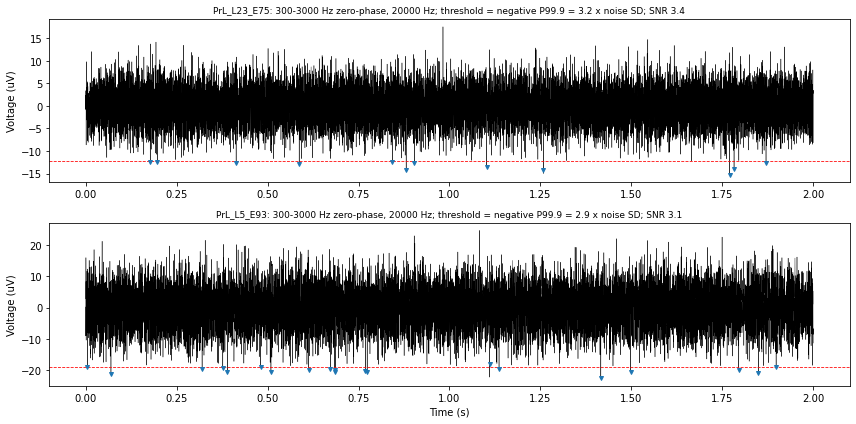

  saved: /home/hosseini/Desktop/CNN/Spike Detection/Output/KO/spike_detection/2024-01-22_mPFC_Slice1__2024-01-22mPFC_Slice1_LC_to_mPFC_hsyn_ChR2_eYFP_Vehicle_KO__0005/figures/2024-01-22_mPFC_Slice1_A2_waveforms.png
  saved: /home/hosseini/Desktop/CNN/Spike Detection/Output/KO/spike_detection/2024-01-22_mPFC_Slice1__2024-01-22mPFC_Slice1_LC_to_mPFC_hsyn_ChR2_eYFP_Vehicle_KO__0005/figures/2024-01-22_mPFC_Slice1_A2_waveforms.pdf


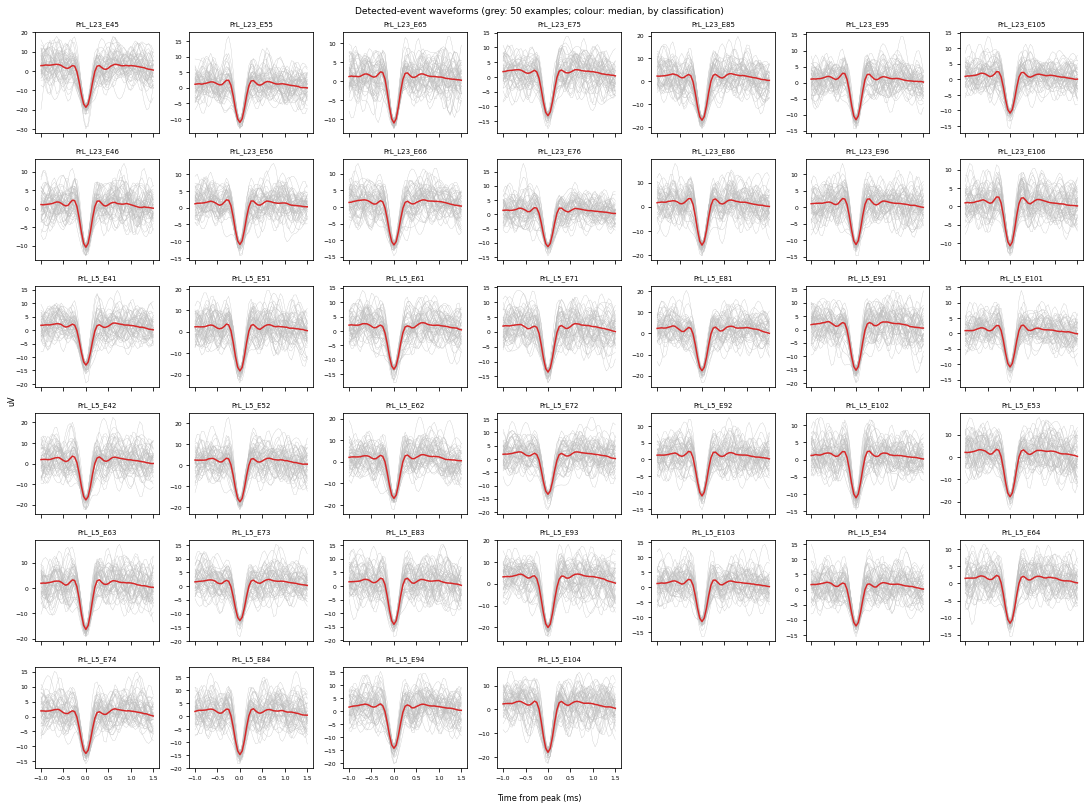

  saved: /home/hosseini/Desktop/CNN/Spike Detection/Output/KO/spike_detection/2024-01-22_mPFC_Slice1__2024-01-22mPFC_Slice1_LC_to_mPFC_hsyn_ChR2_eYFP_Vehicle_KO__0005/figures/2024-01-22_mPFC_Slice1_A3_rates_thresholds_classification.png
  saved: /home/hosseini/Desktop/CNN/Spike Detection/Output/KO/spike_detection/2024-01-22_mPFC_Slice1__2024-01-22mPFC_Slice1_LC_to_mPFC_hsyn_ChR2_eYFP_Vehicle_KO__0005/figures/2024-01-22_mPFC_Slice1_A3_rates_thresholds_classification.pdf


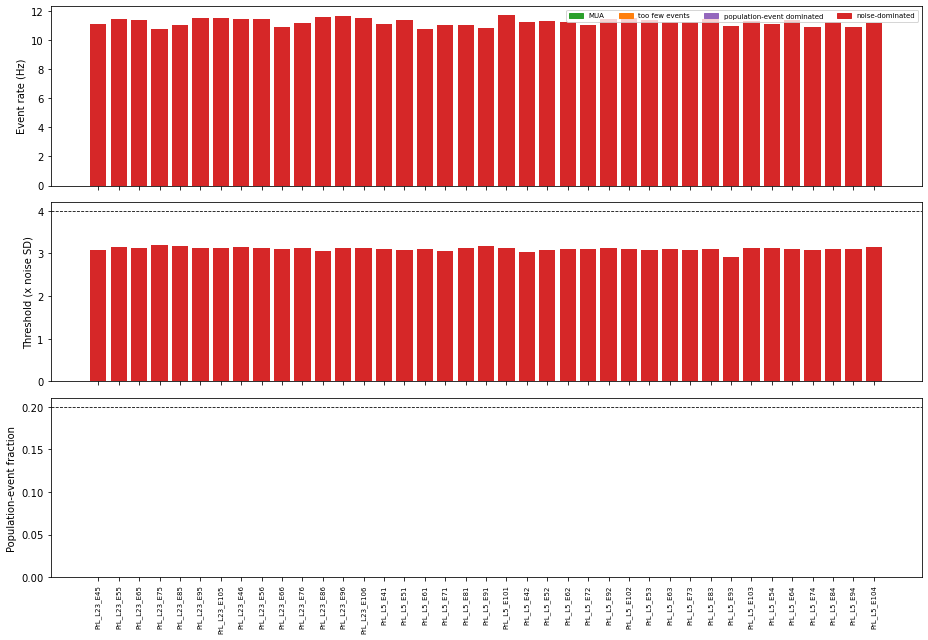

  saved: /home/hosseini/Desktop/CNN/Spike Detection/Output/KO/spike_detection/2024-01-22_mPFC_Slice1__2024-01-22mPFC_Slice1_LC_to_mPFC_hsyn_ChR2_eYFP_Vehicle_KO__0005/figures/2024-01-22_mPFC_Slice1_A4_raster.png
  saved: /home/hosseini/Desktop/CNN/Spike Detection/Output/KO/spike_detection/2024-01-22_mPFC_Slice1__2024-01-22mPFC_Slice1_LC_to_mPFC_hsyn_ChR2_eYFP_Vehicle_KO__0005/figures/2024-01-22_mPFC_Slice1_A4_raster.pdf


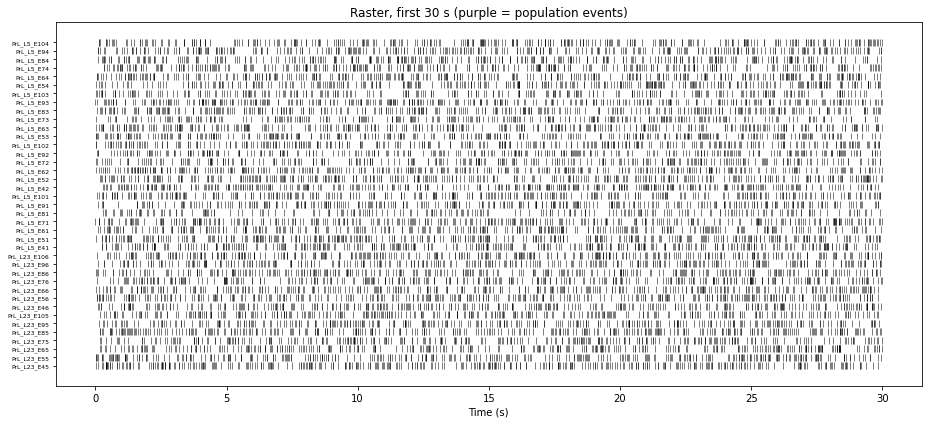

  saved: /home/hosseini/Desktop/CNN/Spike Detection/Output/KO/spike_detection/2024-01-22_mPFC_Slice1__2024-01-22mPFC_Slice1_LC_to_mPFC_hsyn_ChR2_eYFP_Vehicle_KO__0005/figures/2024-01-22_mPFC_Slice1_A5_rate_stationarity.png
  saved: /home/hosseini/Desktop/CNN/Spike Detection/Output/KO/spike_detection/2024-01-22_mPFC_Slice1__2024-01-22mPFC_Slice1_LC_to_mPFC_hsyn_ChR2_eYFP_Vehicle_KO__0005/figures/2024-01-22_mPFC_Slice1_A5_rate_stationarity.pdf


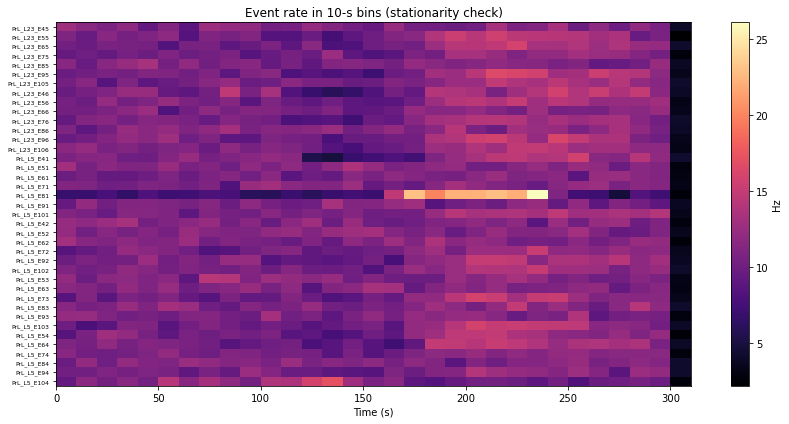

  saved: /home/hosseini/Desktop/CNN/Spike Detection/Output/KO/spike_detection/2024-01-22_mPFC_Slice1__2024-01-22mPFC_Slice1_LC_to_mPFC_hsyn_ChR2_eYFP_Vehicle_KO__0005/figures/2024-01-22_mPFC_Slice1_A6_sufficiency.png
  saved: /home/hosseini/Desktop/CNN/Spike Detection/Output/KO/spike_detection/2024-01-22_mPFC_Slice1__2024-01-22mPFC_Slice1_LC_to_mPFC_hsyn_ChR2_eYFP_Vehicle_KO__0005/figures/2024-01-22_mPFC_Slice1_A6_sufficiency.pdf


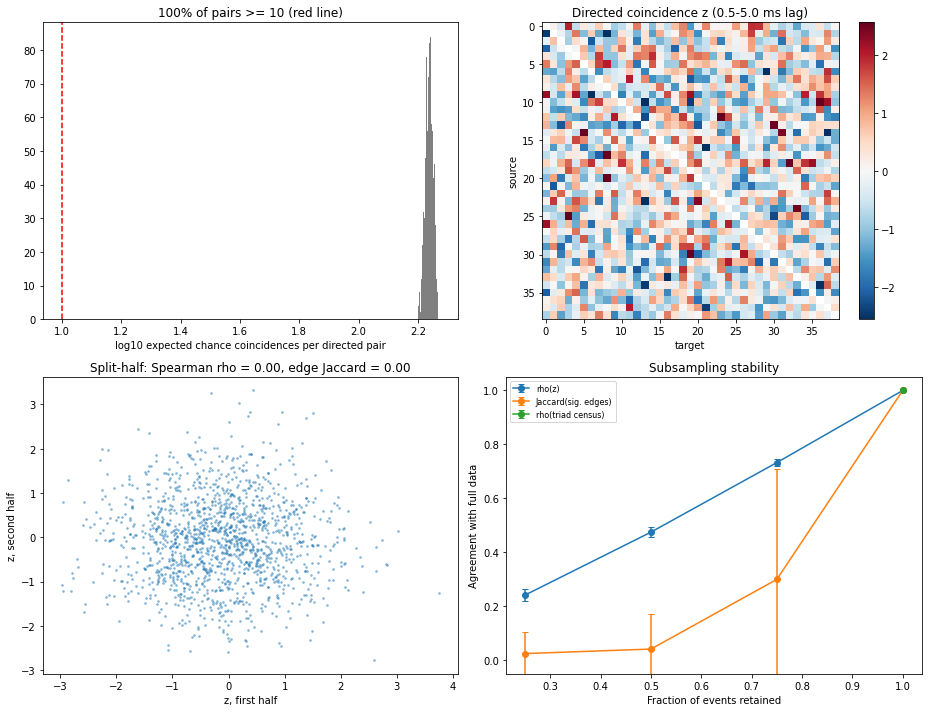

In [10]:
CLASS_COLORS = {"MUA": "tab:green", "too few events": "tab:orange",
                "population-event dominated": "tab:purple"}
def _ccol(c):
    return CLASS_COLORS.get(c, "tab:red")   # noise-dominated -> red

# ---- 9a. Example filtered traces with threshold and detected events (best / worst SNR channel)
ranked = df_ch.dropna(subset=["snr_peak"]).sort_values("snr_peak")
ex_keys = list(dict.fromkeys([ranked["key"].iloc[-1], ranked["key"].iloc[0]])) if len(ranked) else []
if ex_keys:
    fig, axs = plt.subplots(len(ex_keys), 1, figsize=(12, 3 * len(ex_keys)), squeeze=False)
    for ax, k in zip(axs[:, 0], ex_keys):
        tr = example_traces[k]; tt = np.arange(len(tr)) / sf
        ax.plot(tt, tr, lw=0.4, color="k")
        for th in thr_signed_by_key[k]:
            ax.axhline(th, color="r", ls="--", lw=0.8)
        ev = spike_times[k][spike_times[k] < EXAMPLE_TRACE_S]
        ax.plot(ev, tr[(ev * sf).astype(int)], "v", color="tab:blue", ms=4)
        r = df_ch.set_index("key").loc[k]
        ax.set_title(f"{k}: {SPIKE_BAND_HZ[0]:.0f}-{SPIKE_BAND_HZ[1]:.0f} Hz zero-phase, {sf} Hz; "
                     f"threshold = {THRESHOLD_SIGNAL} P{THRESHOLD_PERCENTILE} = {r.threshold_x_noise_sd:.1f} x noise SD; "
                     f"SNR {r.snr_peak:.1f}", fontsize=9)
        ax.set_ylabel(f"Voltage ({UNITS})")
    axs[-1, 0].set_xlabel("Time (s)")
    fig.tight_layout(); save_fig(fig, "A1_example_traces_threshold"); plt.show()

# ---- 9b. Waveforms per channel
keys_wf = [k for k in CH_KEYS if k in median_wfs]
if keys_wf:
    ncol = 7; nrow = int(np.ceil(len(keys_wf) / ncol))
    fig, axs = plt.subplots(nrow, ncol, figsize=(2.2 * ncol, 1.9 * nrow), sharex=True, squeeze=False)
    cls = df_ch.set_index("key")["classification"]
    for ax, k in zip(axs.flat, keys_wf):
        ax.plot(wf_t_ms, example_wfs[k].T, color="0.75", lw=0.3)
        ax.plot(wf_t_ms, median_wfs[k], color=_ccol(cls[k]), lw=1.5)
        ax.set_title(k, fontsize=7); ax.tick_params(labelsize=6)
    for ax in axs.flat[len(keys_wf):]:
        ax.axis("off")
    fig.suptitle(f"Detected-event waveforms (grey: {N_WAVEFORMS_TO_PLOT} examples; colour: median, by classification)", fontsize=9)
    fig.supxlabel("Time from peak (ms)", fontsize=8); fig.supylabel(UNITS, fontsize=8)
    fig.tight_layout(); save_fig(fig, "A2_waveforms"); plt.show()

# ---- 9c. Rates, thresholds in noise-SD units, population-event fraction
fig, axs = plt.subplots(3, 1, figsize=(13, 9), sharex=True)
xs = np.arange(len(df_ch)); cols = [_ccol(c) for c in df_ch["classification"]]
axs[0].bar(xs, df_ch["rate_hz"], color=cols); axs[0].set_ylabel("Event rate (Hz)")
axs[1].bar(xs, df_ch["threshold_x_noise_sd"], color=cols)
axs[1].axhline(MIN_THRESHOLD_IN_NOISE_SD, color="k", ls="--", lw=0.8); axs[1].set_ylabel("Threshold (x noise SD)")
axs[2].bar(xs, df_ch["pop_event_fraction"], color=cols)
axs[2].axhline(MAX_POP_EVENT_FRACTION, color="k", ls="--", lw=0.8); axs[2].set_ylabel("Population-event fraction")
axs[2].set_xticks(xs); axs[2].set_xticklabels(df_ch["key"], rotation=90, fontsize=7)
handles = [plt.Rectangle((0, 0), 1, 1, color=c) for c in list(CLASS_COLORS.values()) + ["tab:red"]]
axs[0].legend(handles, list(CLASS_COLORS) + ["noise-dominated"], fontsize=7, ncol=4)
fig.tight_layout(); save_fig(fig, "A3_rates_thresholds_classification"); plt.show()

# ---- 9d. Raster (first 30 s) with population events
fig, ax = plt.subplots(figsize=(13, 6))
win = min(30.0, duration_s)
for i, k in enumerate(CH_KEYS):
    t = spike_times[k]; m = t < win
    ax.vlines(t[m], i + 0.1, i + 0.9, color=np.where(is_pop[k][m], "tab:purple", "k"), lw=0.5)
ax.set_yticks(np.arange(n_ch) + 0.5); ax.set_yticklabels(CH_KEYS, fontsize=6)
ax.set_xlabel("Time (s)"); ax.set_title(f"Raster, first {win:.0f} s (purple = population events)")
fig.tight_layout(); save_fig(fig, "A4_raster"); plt.show()

# ---- 9e. Rate stationarity
edges = np.arange(0, duration_s + RATE_BIN_S, RATE_BIN_S)
rate_mat = np.array([np.histogram(spike_times[k], edges)[0] / RATE_BIN_S for k in CH_KEYS])
fig, ax = plt.subplots(figsize=(12, 6))
im = ax.imshow(rate_mat, aspect="auto", cmap="magma", extent=[0, edges[-1], n_ch, 0])
ax.set_yticks(np.arange(n_ch) + 0.5); ax.set_yticklabels(CH_KEYS, fontsize=6)
ax.set_xlabel("Time (s)"); ax.set_title(f"Event rate in {RATE_BIN_S:.0f}-s bins (stationarity check)")
fig.colorbar(im, ax=ax, label="Hz"); fig.tight_layout(); save_fig(fig, "A5_rate_stationarity"); plt.show()

# ---- 9f. Sufficiency
fig, axs = plt.subplots(2, 2, figsize=(13, 10))
Epos = df_pairs["expected"].values; Epos = Epos[Epos > 0]
if len(Epos):
    axs[0, 0].hist(np.log10(Epos), bins=40, color="0.5")
axs[0, 0].axvline(np.log10(MIN_EXPECTED_COINCIDENCES), color="r", ls="--")
axs[0, 0].set_xlabel("log10 expected chance coincidences per directed pair")
axs[0, 0].set_title(f"{100*frac_pairs_adequate:.0f}% of pairs >= {MIN_EXPECTED_COINCIDENCES} (red line)")
vmax = np.nanpercentile(np.abs(Z_full), 99) if np.isfinite(Z_full).any() else 1
im = axs[0, 1].imshow(Z_full, cmap="RdBu_r", vmin=-vmax, vmax=vmax)
axs[0, 1].set_title(f"Directed coincidence z ({CONN_LAG_WINDOW_MS[0]}-{CONN_LAG_WINDOW_MS[1]} ms lag)")
axs[0, 1].set_xlabel("target"); axs[0, 1].set_ylabel("source"); fig.colorbar(im, ax=axs[0, 1])
m = offdiag & np.isfinite(Z1) & np.isfinite(Z2)
axs[1, 0].scatter(Z1[m], Z2[m], s=3, alpha=0.4)
axs[1, 0].set_xlabel("z, first half"); axs[1, 0].set_ylabel("z, second half")
axs[1, 0].set_title(f"Split-half: Spearman rho = {rho_half:.2f}, edge Jaccard = {jacc_half:.2f}")
fr = np.r_[df_sub_summary["fraction"], 1.0]
for col, lab in [("rho_z_vs_full", "rho(z)"), ("jaccard_sig_edges_vs_full", "Jaccard(sig. edges)"),
                 ("rho_triad_census_vs_full", "rho(triad census)")]:
    mu = np.r_[df_sub_summary[f"{col}_mean"], 1.0]; sd = np.r_[df_sub_summary[f"{col}_std"], 0.0]
    axs[1, 1].errorbar(fr, mu, yerr=sd, marker="o", capsize=3, label=lab)
axs[1, 1].set_xlabel("Fraction of events retained"); axs[1, 1].set_ylabel("Agreement with full data")
axs[1, 1].set_ylim(-0.05, 1.05); axs[1, 1].legend(fontsize=8); axs[1, 1].set_title("Subsampling stability")
fig.tight_layout(); save_fig(fig, "A6_sufficiency"); plt.show()

### 10. Save all Part-A tables, event times, parameters, and the auto-filled Methods / reviewer response

In [11]:
# ---- per-layer summary
def _iqr(s):
    return f"{s.quantile(0.25):.2f}-{s.quantile(0.75):.2f}"
df_layer = (df_ch.groupby("layer")
            .agg(n_channels=("key", "size"),
                 n_MUA_channels=("classification", lambda s: int((s == "MUA").sum())),
                 total_events=("n_events", "sum"),
                 median_events_per_channel=("n_events", "median"),
                 min_events_per_channel=("n_events", "min"),
                 median_rate_hz=("rate_hz", "median"), iqr_rate_hz=("rate_hz", _iqr),
                 median_rate_hz_excl_pop=("rate_hz_excl_pop", "median"),
                 median_threshold_x_noise_sd=("threshold_x_noise_sd", "median"),
                 median_snr=("snr_peak", "median"),
                 median_pop_event_fraction=("pop_event_fraction", "median"))
            .reset_index())
df_layer.insert(0, "sample_id", SAMPLE_ID); df_layer.insert(1, "genotype", GENOTYPE)

# long-format event table
ev_rows = []
for k in CH_KEYS:
    ev_rows.append(pd.DataFrame({"key": k, "layer": layer_of[k], "time_s": spike_times[k],
                                 "peak_uV": spike_amps[k], "n_coincident_channels": n_coinc[k],
                                 "population_event": is_pop[k]}))
df_events = pd.concat(ev_rows, ignore_index=True) if ev_rows else pd.DataFrame()

for col, val in (("sample_id", SAMPLE_ID), ("genotype", GENOTYPE), ("condition", CONDITION)):
    df_ch.insert(0, col, val) if col not in df_ch else None

save_csv(df_ch, "per_channel_summary")
save_csv(df_layer, "per_layer_summary")
save_csv(df_sens, "threshold_sensitivity")
save_csv(df_events, "all_events")
save_csv(df_pop, "population_events")
save_csv(df_pairs, "pairwise_sufficiency")
save_csv(df_trip_summary, "triplet_sufficiency")
save_csv(df_sub, "subsampling_stability_reps")
save_csv(df_sub_summary, "subsampling_stability")
save_json(suff, "sufficiency_summary")

p = os.path.join(OUT_DIR, f"{SAMPLE_ID}_spike_times.npz"); np.savez_compressed(p, **spike_times); _record(p)
p = os.path.join(OUT_DIR, f"{SAMPLE_ID}_median_waveforms.npz")
np.savez_compressed(p, t_ms=wf_t_ms, **median_wfs); _record(p)
p = os.path.join(OUT_DIR, f"{SAMPLE_ID}_connectivity_full.npz")
np.savez_compressed(p, keys=np.array(CH_KEYS), C=C_full, E=E_full, Z=Z_full, Z_half1=Z1, Z_half2=Z2); _record(p)

THRESHOLD_DESCRIPTION = {
    "negative": f"signed band-passed voltage; events = samples below the {100-THRESHOLD_PERCENTILE:g}th percentile "
                f"(negative-going deflections only)",
    "positive": f"signed band-passed voltage; events = samples above the {THRESHOLD_PERCENTILE:g}th percentile "
                f"(positive-going deflections only)",
    "absolute": f"absolute band-passed voltage |x|; events = samples above the {THRESHOLD_PERCENTILE:g}th percentile of |x| "
                f"(either polarity)",
}[THRESHOLD_SIGNAL]

params = {
    "recording": {"file": RECORDING_FILE, "sample_id": SAMPLE_ID, "genotype": GENOTYPE, "condition": CONDITION,
                  "n_channels_in_file": n_rows, "sampling_rate_hz": sf, "duration_s": duration_s, "units": UNITS,
                  "channel_map_mismatches": map_mismatches, "excluded_electrodes": unwanted_num,
                  "layers": {k: [row_to_label[r] for r in v] for k, v in LAYERS.items()}},
    "detection": {"signal": "wideband extracellular voltage (MEA), converted to uV",
                  "filter": f"Butterworth band-pass {SPIKE_BAND_HZ[0]}-{SPIKE_BAND_HZ[1]} Hz, order {SPIKE_FILTER_ORDER}, "
                            f"second-order sections, zero-phase forward-backward (scipy.signal.sosfiltfilt)",
                  "detection_sampling_rate_hz": sf, "downsampled_for_detection": DOWNSAMPLE_FOR_DETECTION,
                  "threshold_signal_representation": THRESHOLD_SIGNAL,
                  "threshold_description": THRESHOLD_DESCRIPTION,
                  "threshold_percentile": THRESHOLD_PERCENTILE,
                  "threshold_computed_over": "entire recording, separately for each channel",
                  "event_definition": "one event per contiguous supra-threshold run, timed at its extremum",
                  "dead_time_ms": DEAD_TIME_MS,
                  "noise_estimate": "median(|x|)/0.6745 (Quiroga et al., 2004)",
                  "spike_sorting": "none - events are multi-unit activity (MUA), not single units"},
    "validation": {"population_event_coincidence_ms": POP_COINCIDENCE_MS,
                   "population_event_min_channels": pop_min_channels,
                   "MUA_min_threshold_x_noise_sd": MIN_THRESHOLD_IN_NOISE_SD,
                   "MUA_max_population_event_fraction": MAX_POP_EVENT_FRACTION,
                   "min_events_per_channel": MIN_EVENTS_PER_CHANNEL,
                   "isi_violation_ms": ISI_VIOLATION_MS,
                   "waveform_window_ms": [-WAVEFORM_PRE_MS, WAVEFORM_POST_MS]},
    "sufficiency": {"lag_window_ms": CONN_LAG_WINDOW_MS, "z_threshold": CONN_Z_THRESHOLD,
                    "min_expected_coincidences": MIN_EXPECTED_COINCIDENCES,
                    "subsample_fractions": SUBSAMPLE_FRACTIONS, "n_subsample_reps": N_SUBSAMPLE_REPS,
                    "random_seed": RANDOM_SEED},
    "software": {"python": platform.python_version(), "numpy": np.__version__, "scipy": scipy.__version__,
                 "pandas": pd.__version__, "h5py": h5py.__version__, "tensorly": tl.__version__,
                 "networkx": nx.__version__ if HAVE_NX else None},
    "run_timestamp": datetime.datetime.now().isoformat(timespec="seconds"),
}
save_json(params, "detection_parameters")

  saved: /home/hosseini/Desktop/CNN/Spike Detection/Output/KO/spike_detection/2024-01-22_mPFC_Slice1__2024-01-22mPFC_Slice1_LC_to_mPFC_hsyn_ChR2_eYFP_Vehicle_KO__0005/2024-01-22_mPFC_Slice1_per_channel_summary.csv
  saved: /home/hosseini/Desktop/CNN/Spike Detection/Output/KO/spike_detection/2024-01-22_mPFC_Slice1__2024-01-22mPFC_Slice1_LC_to_mPFC_hsyn_ChR2_eYFP_Vehicle_KO__0005/2024-01-22_mPFC_Slice1_per_layer_summary.csv
  saved: /home/hosseini/Desktop/CNN/Spike Detection/Output/KO/spike_detection/2024-01-22_mPFC_Slice1__2024-01-22mPFC_Slice1_LC_to_mPFC_hsyn_ChR2_eYFP_Vehicle_KO__0005/2024-01-22_mPFC_Slice1_threshold_sensitivity.csv
  saved: /home/hosseini/Desktop/CNN/Spike Detection/Output/KO/spike_detection/2024-01-22_mPFC_Slice1__2024-01-22mPFC_Slice1_LC_to_mPFC_hsyn_ChR2_eYFP_Vehicle_KO__0005/2024-01-22_mPFC_Slice1_all_events.csv
  saved: /home/hosseini/Desktop/CNN/Spike Detection/Output/KO/spike_detection/2024-01-22_mPFC_Slice1__2024-01-22mPFC_Slice1_LC_to_mPFC_hsyn_ChR2_eYFP_Veh

In [12]:
# ---- Methods paragraph + reviewer answers, filled with this recording's numbers
r = df_ch
mua = r[r["classification"] == "MUA"]
def q(s, f="{:.2f}"):
    return f"{f.format(s.median())} (IQR {f.format(s.quantile(.25))}-{f.format(s.quantile(.75))}; range {f.format(s.min())}-{f.format(s.max())})"

layer_lines = "\n".join(
    f"| {row.layer} | {row.n_channels} | {row.n_MUA_channels} | {int(row.total_events)} | "
    f"{row.median_events_per_channel:.0f} | {row.median_rate_hz:.2f} ({row.iqr_rate_hz}) | "
    f"{row.median_rate_hz_excl_pop:.2f} | {row.median_threshold_x_noise_sd:.1f} |"
    for row in df_layer.itertuples())
sens_cols = [c for c in df_sens.columns if c.startswith("n_")]
sens_lines = "\n".join(f"| `{c}` | {df_sens[c].median():.0f} | {df_sens[c].sum():.0f} |" for c in sens_cols)

methods = f"""
## Methods (auto-generated for {SAMPLE_ID}, {GENOTYPE}, {CONDITION}; recording `{RECORDING_FILE}`)

**Spike (multi-unit) event detection.** Extracellular signals were acquired at {sf} Hz on a 60-electrode MEA and
converted to µV using the per-channel conversion factors stored with the recording. For event detection, each channel
was band-pass filtered between {SPIKE_BAND_HZ[0]:.0f} and {SPIKE_BAND_HZ[1]:.0f} Hz with a {SPIKE_FILTER_ORDER}th-order
Butterworth filter (second-order sections) applied forward and backward (zero phase; scipy.signal.sosfiltfilt).
Detection was performed at the native {sf}-Hz sampling rate; data were **not downsampled** for detection (only the
separate 1–500 Hz LFP stream used for gamma/HFO power was downsampled, to {LFP_TARGET_FS} Hz). The amplitude-percentile
threshold was applied to the **{THRESHOLD_DESCRIPTION}**, computed separately for each channel over the entire
{duration_s:.0f}-s recording. Each contiguous supra-threshold run was counted as one event, timed at its extremum,
and a {DEAD_TIME_MS:g}-ms dead time was imposed. Expressed relative to the robust noise SD (median|x|/0.6745;
Quiroga et al., 2004), thresholds were {q(r['threshold_x_noise_sd'], '{:.1f}')} × noise SD across the {n_ch} analysed channels.

**Nature of events and validation.** No spike sorting was performed; detected events therefore represent
**multi-unit activity (MUA)** and are not attributed to single neurons. To separate local MUA from sharp
population-level field events, each event was tested for coincidence (±{POP_COINCIDENCE_MS} ms) with events on the
other analysed channels; events present on ≥ {pop_min_channels}/{n_ch} channels were classified as population events
({len(df_pop)} events, {len(df_pop)/duration_s:.3f} Hz). Channels were retained as MUA when the threshold was
≥ {MIN_THRESHOLD_IN_NOISE_SD:g} × noise SD, ≥ {MIN_EVENTS_PER_CHANNEL} events were detected, and ≤ {100*MAX_POP_EVENT_FRACTION:.0f}%
of events were population events; {len(mua)}/{n_ch} channels met these criteria. Median waveforms were inspected for
spike-like morphology (trough-to-peak width {q(r['trough_to_peak_ms'], '{:.2f}')} ms; peak SNR
{q(r['snr_peak'], '{:.1f}')}).

**Event counts and rates.** Channels yielded {q(r['n_events'], '{:.0f}')} events in {duration_s/60:.1f} min,
i.e. {q(r['rate_hz'])} Hz (excluding population events: {q(r['rate_hz_excl_pop'])} Hz).

**Sampling adequacy.** For directed connectivity (lag window {CONN_LAG_WINDOW_MS[0]}–{CONN_LAG_WINDOW_MS[1]} ms), the number
of coincidences expected by chance was ≥ {MIN_EXPECTED_COINCIDENCES} for {100*frac_pairs_adequate:.1f}% of
{len(df_pairs)} directed pairs (median {suff['median_expected_coincidences']:.1f}; median minimum detectable excess at
z = {CONN_Z_THRESHOLD:g}: {100*suff['median_min_detectable_rel_excess']:.0f}% above chance), and
{100*frac_trip_adequate:.1f}% of {len(df_trip)} channel triplets had all three pairs adequately sampled. Connectivity
estimated independently from the two halves of the recording agreed with Spearman ρ = {rho_half:.2f} (Jaccard overlap
of significant edges {jacc_half:.2f}; triad-census ρ = {rho_triad_half:.2f}). Under the pre-specified criteria
(≥ {100*SUFF_MIN_FRAC_PAIRS_ADEQUATE:.0f}% adequate pairs and split-half {SUFF_RELIABILITY_METRIC} ≥ {SUFF_MIN_SPLIT_HALF_RELIABILITY}), the recording was
judged **{'sufficient' if sufficient else 'NOT sufficient'}** for connectivity/motif estimation.

### Per-layer summary
| Layer | Channels | MUA channels | Total events | Median events/ch | Median rate Hz (IQR) | Median rate excl. pop. | Median thr (× noise SD) |
|---|---|---|---|---|---|---|---|
{layer_lines}

### Threshold sensitivity (events per channel under alternative definitions)
| Definition | Median per channel | Total |
|---|---|---|
{sens_lines}

## Point-by-point answers
* **Underlying signal / filter / sampling rate:** wideband MEA voltage in µV, {SPIKE_BAND_HZ[0]:.0f}–{SPIKE_BAND_HZ[1]:.0f} Hz
  zero-phase Butterworth (order {SPIKE_FILTER_ORDER}), detection at {sf} Hz.
* **Downsampled?** No (detection at native rate). The LFP stream for band-power analysis was downsampled to {LFP_TARGET_FS} Hz.
* **Signal representation for the threshold:** {THRESHOLD_DESCRIPTION}.
* **Single units vs MUA vs population events:** MUA (no sorting); population-level synchronous events identified by
  cross-channel coincidence and reported separately ({len(df_pop)} events).
* **Sorting / validation:** no sorting; validation by noise-referenced threshold level, waveform morphology/SNR,
  ISI distribution, cross-channel coincidence, and threshold-sensitivity analysis.
* **Number and rate of events:** see tables above and `per_channel_summary.csv`.
* **Sufficient events in 5 min?** {'Yes' if sufficient else 'No'} by the criteria above; see `sufficiency_summary.json`
  and figure A6.
"""
p = os.path.join(OUT_DIR, f"{SAMPLE_ID}_METHODS_and_reviewer_response.md")
with open(p, "w") as f:
    f.write(methods)
_record(p)
print(methods)

  saved: /home/hosseini/Desktop/CNN/Spike Detection/Output/KO/spike_detection/2024-01-22_mPFC_Slice1__2024-01-22mPFC_Slice1_LC_to_mPFC_hsyn_ChR2_eYFP_Vehicle_KO__0005/2024-01-22_mPFC_Slice1_METHODS_and_reviewer_response.md

## Methods (auto-generated for 2024-01-22_mPFC_Slice1, KO, Baseline; recording `/home/hosseini/Desktop/2024/CNN_samples/2024-01-22mPFC_Slice1_LC_to_mPFC_hsyn_ChR2_eYFP_Vehicle_KO__0005.h5`)

**Spike (multi-unit) event detection.** Extracellular signals were acquired at 20000 Hz on a 60-electrode MEA and
converted to µV using the per-channel conversion factors stored with the recording. For event detection, each channel
was band-pass filtered between 300 and 3000 Hz with a 4th-order
Butterworth filter (second-order sections) applied forward and backward (zero phase; scipy.signal.sosfiltfilt).
Detection was performed at the native 20000-Hz sampling rate; data were **not downsampled** for detection (only the
separate 1–500 Hz LFP stream used for gamma/HFO power was dow

# Part B — LFP gamma and HFO band power (original analysis, corrected)

### 11. LFP preprocessing
**Corrected mode (default):** µV → 1–500 Hz Butterworth (sos, zero-phase) at 20 kHz → FIR-decimated to 1 kHz
(anti-aliasing included in `scipy.signal.decimate`) → 60 Hz notch (zero-phase). The returned sampling rate (`fs_lfp`)
is the *only* rate used afterwards.

**Original mode** (`REPRODUCE_ORIGINAL_LFP = True`) repeats the original steps exactly (raw counts, causal `lfilter`,
10 kHz, then analysed as if 1 kHz) so you can compare against previously saved arrays.

In [13]:
def downsample_data(data, fs_in, target_fs):
    """Decimate in integer steps of <= 10 (FIR anti-alias filter, zero phase). Returns (data, new_fs)."""
    factor = int(fs_in / target_fs)
    if factor < 1:
        raise ValueError("Target sampling frequency must be below the original sampling frequency.")
    out, fs_cur = data, fs_in
    while factor > 1:
        step = min(factor, 10)
        out = signal.decimate(out, step, ftype="fir")
        fs_cur = fs_cur / step
        factor = int(fs_cur / target_fs)
    return out, int(fs_cur)

def preprocess_lfp(row):
    if REPRODUCE_ORIGINAL_LFP:
        x = ChannelData_baseline[row].ravel()
        b, a = butter(2, [1 / (sf / 2), 500 / (sf / 2)], btype="bandpass")
        x = lfilter(b, a, x)
        x, fs_out = downsample_data(x, sf, 10000)
        bn, an = iirnotch(60.0 / (fs_out / 2), 30)
        return lfilter(bn, an, x), fs_out
    sos = butter(LFP_FILTER_ORDER, LFP_BAND_HZ, btype="bandpass", fs=sf, output="sos")
    x = sosfiltfilt(sos, to_uV(row))
    x, fs_out = downsample_data(x, sf, LFP_TARGET_FS)
    bn, an = iirnotch(LINE_NOISE_HZ, NOTCH_Q, fs=fs_out)
    return filtfilt(bn, an, x), fs_out

lfp = {}
for layer, rows_ in LAYERS.items():
    out = [preprocess_lfp(r) for r in rows_]
    lfp[layer] = np.array([o[0] for o in out])
    fs_lfp = out[0][1]
PrL23_data, PrL5_data = lfp["PrL_L23"], lfp["PrL_L5"]

if REPRODUCE_ORIGINAL_LFP:
    # Original behaviour: data are at 10 kHz but are analysed as if at 1 kHz with 1000-sample windows.
    bp_fs, bp_win, bp_stride = 1000, 1000, 500
    print(f"ORIGINAL MODE: data at {fs_lfp} Hz analysed with fs={bp_fs} (frequency axis mislabelled x{fs_lfp // bp_fs}).")
else:
    bp_fs, bp_win, bp_stride = fs_lfp, int(BP_WINDOW_S * fs_lfp), int(BP_STRIDE_S * fs_lfp)
print("PrL23", PrL23_data.shape, "| PrL5", PrL5_data.shape, f"| LFP fs = {fs_lfp} Hz | windows {bp_win} samples")

PrL23 (14, 303000) | PrL5 (25, 303000) | LFP fs = 1000 Hz | windows 1000 samples


### 12. Band power + CP rank selection (gamma and HFO)
For each layer: Welch PSD in sliding windows → mean power in the band → channel × window matrix.
CP (PARAFAC) of a 2-D matrix is a rank-R matrix factorisation; rank is chosen by BIC
(`R·(n_ch+n_win)·ln N + 2N·ln(relative error)`, equivalent to the Gaussian BIC up to a constant).
Rows are min-max normalised per channel. With `APPLY_CP_CHANNEL_WEIGHTING = True`, each channel is weighted by
its mean absolute loading on the **channel** mode (`factors[0]`).

GBO PrL_L23 (14 ch): matrix (14, 604), optimal CP rank 5
GBO PrL_L5 (25 ch): matrix (25, 604), optimal CP rank 4
  saved: /home/hosseini/Desktop/CNN/Spike Detection/Output/KO/spike_detection/2024-01-22_mPFC_Slice1__2024-01-22mPFC_Slice1_LC_to_mPFC_hsyn_ChR2_eYFP_Vehicle_KO__0005/figures/2024-01-22_mPFC_Slice1_B_GBO_power.png
  saved: /home/hosseini/Desktop/CNN/Spike Detection/Output/KO/spike_detection/2024-01-22_mPFC_Slice1__2024-01-22mPFC_Slice1_LC_to_mPFC_hsyn_ChR2_eYFP_Vehicle_KO__0005/figures/2024-01-22_mPFC_Slice1_B_GBO_power.pdf


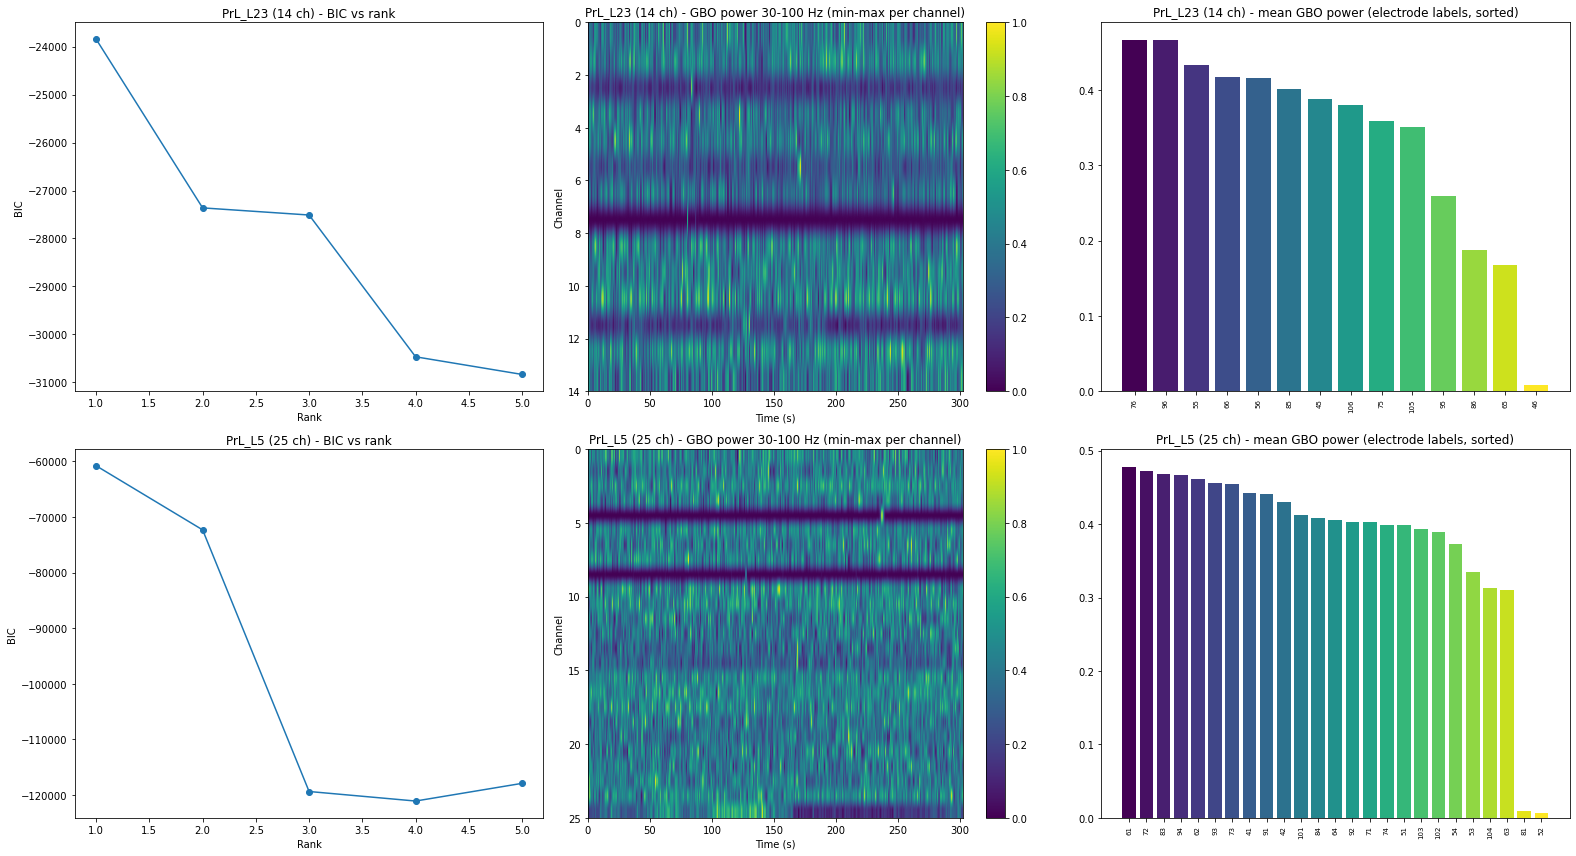

HFO PrL_L23 (14 ch): matrix (14, 604), optimal CP rank 1
HFO PrL_L5 (25 ch): matrix (25, 604), optimal CP rank 2
  saved: /home/hosseini/Desktop/CNN/Spike Detection/Output/KO/spike_detection/2024-01-22_mPFC_Slice1__2024-01-22mPFC_Slice1_LC_to_mPFC_hsyn_ChR2_eYFP_Vehicle_KO__0005/figures/2024-01-22_mPFC_Slice1_B_HFO_power.png
  saved: /home/hosseini/Desktop/CNN/Spike Detection/Output/KO/spike_detection/2024-01-22_mPFC_Slice1__2024-01-22mPFC_Slice1_LC_to_mPFC_hsyn_ChR2_eYFP_Vehicle_KO__0005/figures/2024-01-22_mPFC_Slice1_B_HFO_power.pdf


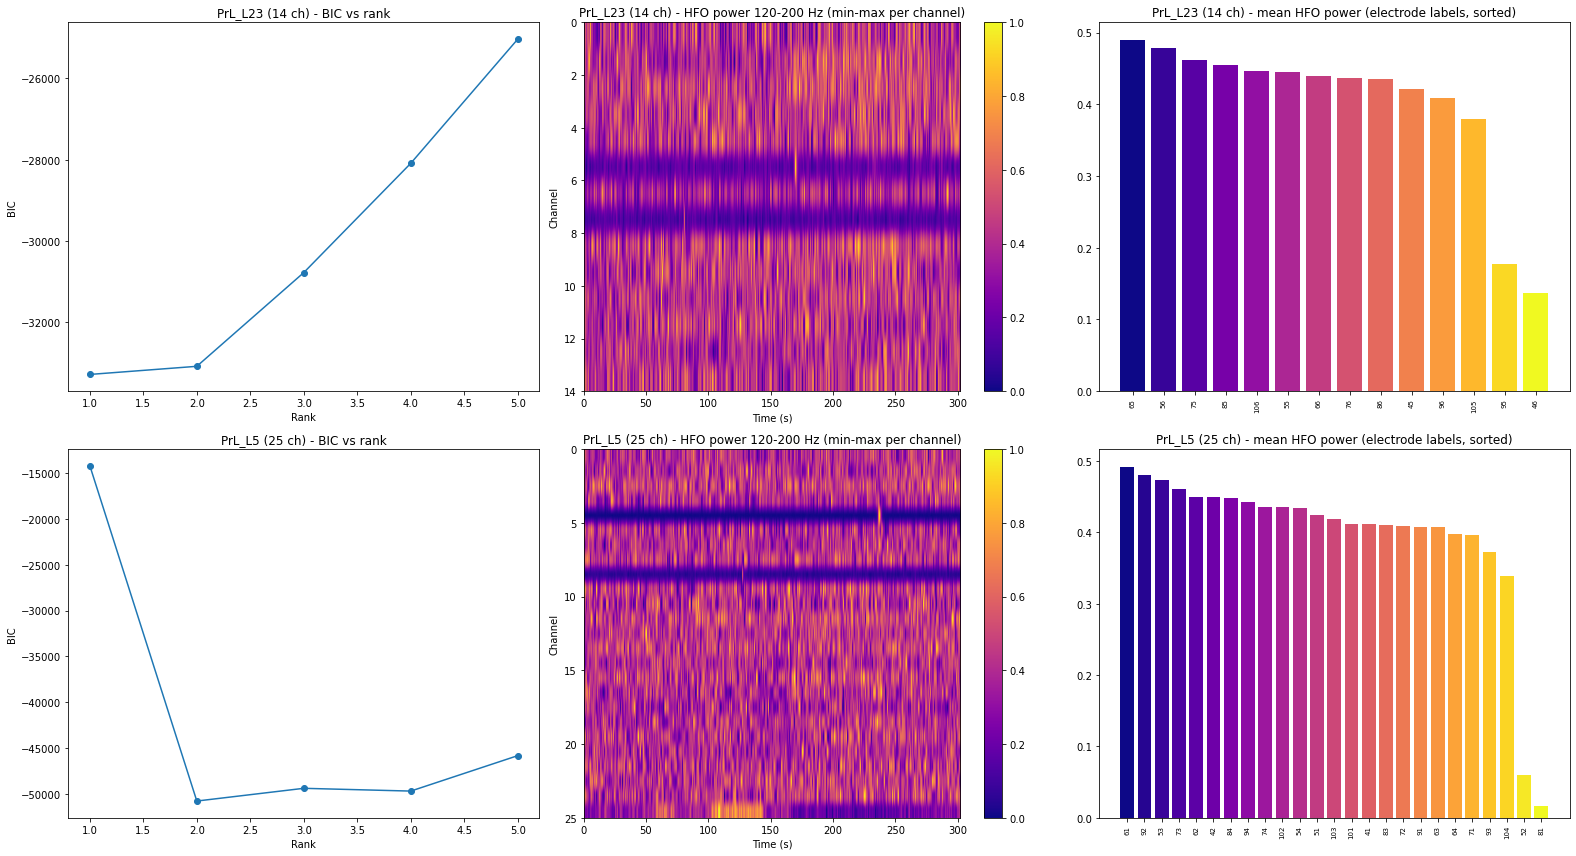

In [14]:
def band_power_matrix(data, band):
    out = []
    for ch in data:
        row = []
        for s in range(0, data.shape[1] - bp_win, bp_stride):
            f, P = welch(ch[s:s + bp_win], fs=bp_fs, nperseg=WELCH_NPERSEG)
            row.append(np.mean(P[(f >= band[0]) & (f <= band[1])]))
        out.append(row)
    return np.array(out)

def bic(n_params, rel_error, n):
    return n_params * np.log(n) + 2 * n * np.log(rel_error + 1e-16)

def run_band(band, band_name, cmap):
    results, bic_curves = {}, {}
    fig, axs = plt.subplots(len(LAYERS), 3, figsize=(22, 6 * len(LAYERS)), squeeze=False)
    for i, (layer, data) in enumerate(lfp.items()):
        P = band_power_matrix(data, band)
        T = tl.tensor(P); N = np.prod(T.shape); bics = []
        for rank in CP_RANKS:
            try:
                fac = parafac(T, rank=rank)
                err = tl.norm(T - tl.cp_to_tensor(fac)) / (tl.norm(T) + 1e-16)
                bics.append(bic(rank * sum(T.shape), err, N))
            except Exception as e:
                print(f"  rank {rank} failed for {layer}: {e}"); bics.append(np.inf)
        opt = list(CP_RANKS)[int(np.argmin(bics))]
        bic_curves[layer] = {"ranks": list(CP_RANKS), "bic": bics, "optimal_rank": opt}
        norm = MinMaxScaler().fit_transform(P.T).T          # per-channel min-max over time
        if APPLY_CP_CHANNEL_WEIGHTING:
            fac = parafac(tl.tensor(norm), rank=opt)
            w = np.mean(np.abs(fac.factors[0]), axis=1)    # channel-mode loadings (n_channels,)
            combined = norm * w[:, None]
        else:
            combined = norm                                # what the original notebook actually saved
        results[layer] = combined
        name = f"{layer} ({data.shape[0]} ch)"
        print(f"{band_name} {name}: matrix {P.shape}, optimal CP rank {opt}")

        axs[i, 0].plot(list(CP_RANKS), bics, "o-"); axs[i, 0].set_title(f"{name} - BIC vs rank")
        axs[i, 0].set_xlabel("Rank"); axs[i, 0].set_ylabel("BIC")
        t_end = combined.shape[1] * bp_stride / bp_fs
        im = axs[i, 1].imshow(combined, aspect="auto", cmap=cmap, extent=[0, t_end, data.shape[0], 0])
        axs[i, 1].set_title(f"{name} - {band_name} power {band[0]}-{band[1]} Hz (min-max per channel)")
        axs[i, 1].set_xlabel("Time (s)"); axs[i, 1].set_ylabel("Channel"); fig.colorbar(im, ax=axs[i, 1])
        mp = combined.mean(axis=1); order_ = np.argsort(mp)[::-1]
        axs[i, 2].bar(range(len(mp)), mp[order_], color=plt.get_cmap(cmap)(np.linspace(0, 1, len(mp))))
        axs[i, 2].set_xticks(range(len(mp)))
        axs[i, 2].set_xticklabels([row_to_label[LAYERS[layer][k]] for k in order_], rotation=90, fontsize=7)
        axs[i, 2].set_title(f"{name} - mean {band_name} power (electrode labels, sorted)")
    fig.tight_layout(); save_fig(fig, f"B_{band_name}_power"); plt.show()
    return results, bic_curves

gbo, gbo_bic = run_band(GAMMA_BAND_HZ, "GBO", "viridis")
hfo, hfo_bic = run_band(HFO_BAND_HZ, "HFO", "plasma")
combined_power_PrL23_GBO, combined_power_PrL5_GBO = gbo["PrL_L23"], gbo["PrL_L5"]
combined_power_PrL23_HFO, combined_power_PrL5_HFO = hfo["PrL_L23"], hfo["PrL_L5"]

### 13. Save LFP outputs, LFP parameters, and the run manifest

In [15]:
files_to_save = {
    f"{SAMPLE_ID}_PrL23_GBO.npy": combined_power_PrL23_GBO,
    f"{SAMPLE_ID}_PrL5_GBO.npy":  combined_power_PrL5_GBO,
    f"{SAMPLE_ID}_PrL23_HFO.npy": combined_power_PrL23_HFO,
    f"{SAMPLE_ID}_PrL5_HFO.npy":  combined_power_PrL5_HFO,
}
for fname, arr in files_to_save.items():
    p = os.path.join(LFP_OUT_DIR, fname); np.save(p, arr); _record(p)

lfp_params = {
    "mode": "original (uncorrected)" if REPRODUCE_ORIGINAL_LFP else "corrected",
    "filter": ("Butterworth 1-500 Hz order 2, (b,a), causal lfilter" if REPRODUCE_ORIGINAL_LFP else
               f"Butterworth {LFP_BAND_HZ[0]}-{LFP_BAND_HZ[1]} Hz order {LFP_FILTER_ORDER}, sos, zero-phase"),
    "lfp_sampling_rate_hz": fs_lfp, "fs_used_for_welch_hz": bp_fs,
    "window_samples": bp_win, "stride_samples": bp_stride,
    "window_s_true": bp_win / fs_lfp, "welch_nperseg": WELCH_NPERSEG,
    "gamma_band_hz_nominal": GAMMA_BAND_HZ, "hfo_band_hz_nominal": HFO_BAND_HZ,
    "true_band_scaling_factor": fs_lfp / bp_fs,
    "notch_hz": LINE_NOISE_HZ, "notch_Q": NOTCH_Q,
    "normalisation": "per-channel min-max over time windows",
    "cp_channel_weighting_applied": APPLY_CP_CHANNEL_WEIGHTING,
    "bic": {"GBO": gbo_bic, "HFO": hfo_bic},
    "array_layout": "rows = channels in LAYERS order, columns = time windows",
    "row_electrodes": {k: [row_to_label[r] for r in v] for k, v in LAYERS.items()},
}
save_json(lfp_params, "lfp_parameters", LFP_OUT_DIR)

manifest = {"generated": datetime.datetime.now().isoformat(timespec="seconds"), "files": WRITTEN_FILES}
p = os.path.join(OUT_DIR, f"{SAMPLE_ID}_run_manifest.json")
with open(p, "w") as f:
    json.dump(manifest, f, indent=2)
print(f"\nDone. {len(WRITTEN_FILES) + 1} files written; manifest: {p}")

  saved: /home/hosseini/Desktop/CNN/Spike Detection/Output/KO/lfp_power_corrected_fs/2024-01-22_mPFC_Slice1_PrL23_GBO.npy
  saved: /home/hosseini/Desktop/CNN/Spike Detection/Output/KO/lfp_power_corrected_fs/2024-01-22_mPFC_Slice1_PrL5_GBO.npy
  saved: /home/hosseini/Desktop/CNN/Spike Detection/Output/KO/lfp_power_corrected_fs/2024-01-22_mPFC_Slice1_PrL23_HFO.npy
  saved: /home/hosseini/Desktop/CNN/Spike Detection/Output/KO/lfp_power_corrected_fs/2024-01-22_mPFC_Slice1_PrL5_HFO.npy
  saved: /home/hosseini/Desktop/CNN/Spike Detection/Output/KO/lfp_power_corrected_fs/2024-01-22_mPFC_Slice1_lfp_parameters.json

Done. 37 files written; manifest: /home/hosseini/Desktop/CNN/Spike Detection/Output/KO/spike_detection/2024-01-22_mPFC_Slice1__2024-01-22mPFC_Slice1_LC_to_mPFC_hsyn_ChR2_eYFP_Vehicle_KO__0005/2024-01-22_mPFC_Slice1_run_manifest.json
